# The Midnight Queue — Assignment 2 (Design and Analysis of Algorithms)
**Roll no 24i-2625 · Section B · seed s = 242625 · K = 152**

## How to use this notebook (Google Colab)
1. **Upload `creditcard.csv`** to Colab (left sidebar ▸ Files ▸ Upload) or put it in your Google Drive. Do *not* put the dataset in your submission.
2. **First run in `MODE = "quick"`** (cell 1, default): small sizes, takes roughly 15–25 minutes. Use it to check everything works and to write your prediction log.
3. For the final numbers set **`MODE = "full"`** (cell 1) and run again. This uses n = 1,000 / 10,000 / 100,000 / 284,807 and takes **hours**. Every measurement is appended to `results.csv` as soon as it finishes, so if Colab disconnects you can simply *Runtime ▸ Run all* again and it **resumes** where it stopped (set `USE_DRIVE = True` so the results survive a disconnect).
4. `MODE = "smoke"` is a 1–2 minute self-test (tiny sizes, tiny time limit, so it shows DNF handling too).

**Order of the cells follows the assignment:** setup ▸ data ▸ Problem A ▸ Problem B (algorithms + tests) ▸ prediction log ▸ Problem C ▸ D ▸ E ▸ F (maths + numbers) ▸ G ▸ H ▸ package for submission.

**Definitions used everywhere**
* A **comparison** = one evaluation "is key A before key B" (`a[0] < b[0]`).
* A **move** = one write of a record into an array slot (a swap = 2 moves; a swap of a slot with itself is skipped and not counted; copying into a temporary or auxiliary buffer counts).
* Records are `(key, txn_id)`; `Class` is never inside a record or a key.
* Timing and counting happen in the *same* run (the counters are part of every contender, so all contenders carry the same bookkeeping overhead).

In [1]:
# Setup & settings
import os, sys, time, math, csv, gc, random, bisect, platform, tracemalloc, itertools, zipfile, datetime, statistics, hashlib
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# things you may change
MODE = os.environ.get("A2_MODE", "quick")      # "smoke" | "quick" | "full"
USE_DRIVE = False       # True: mount Google Drive and keep results there (recommended for MODE="full")
CSV_PATH = None         # None = look for creditcard.csv automatically (or ask you to upload it)
SKIP_LOG_CHECK = os.environ.get("A2_SKIP_LOG", "0") == "1"   # leave False: the tournament demands a saved (and, in full mode, edited) prediction log
INFER_DNF = True        # if (contender, condition) already DNF'd at size n, larger n are recorded as "DNF_inferred" instead of burning another 5 minutes

ROLL, SECTION = "24i-2625", "B"
S = 242625                       # roll number, digits only
SEED = S                         # every random choice uses this seed
K = 25 + (S % 226)               # shift capacity = 152

_CFG = {
  "smoke": dict(sizes=[300, 1000],               bar_n=1000,  d_sizes=[1000],        e_n=1000,   val_n=1500,  runs=3, limit=0.05),
  "quick": dict(sizes=[1000, 5000],              bar_n=5000,  d_sizes=[10000, 50000], e_n=50000,  val_n=8000,  runs=5, limit=60),
  "full":  dict(sizes=[1000, 10000, 100000, 284807], bar_n=10000, d_sizes=[100000, 284807], e_n=284807, val_n=20000, runs=5, limit=300),
}
assert MODE in _CFG, "MODE must be smoke, quick or full"
CFG = _CFG[MODE]
SIZES, BAR_N, D_SIZES, E_N, VAL_N = CFG["sizes"], CFG["bar_n"], CFG["d_sizes"], CFG["e_n"], CFG["val_n"]
RUNS, TIME_LIMIT = CFG["runs"], float(os.environ.get("A2_LIMIT", CFG["limit"]))      # TIME_LIMIT = DNF threshold per single run, in seconds
CONDS = ["C1", "C2", "C3", "C4", "C5", "C6"]
COND_NAME = {"C1": "Arrival", "C2": "Shuffled", "C3": "Pre-ranked", "C4": "Reverse-ranked", "C5": "Nearly ranked", "C6": "Band-only"}

IN_COLAB = "google.colab" in sys.modules
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = f"/content/drive/MyDrive/A2_results_{MODE}"
else:
    OUT_DIR = f"A2_results_{MODE}"
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9})

def _cpu():
    try:
        for line in open("/proc/cpuinfo"):
            if line.startswith("model name"): return line.split(":", 1)[1].strip()
    except Exception: pass
    return platform.processor() or "unknown CPU"
HARDWARE = f"Client: HP EliteBook (7th-gen Intel Core i5), experiments run in Google Colab (VM CPU: {_cpu()}) | {os.cpu_count()} logical CPUs | Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | {platform.platform()}"
print(f"MODE={MODE}  sizes={SIZES}  runs={RUNS}  DNF limit={TIME_LIMIT}s  K={K}  seed={SEED}")
print("Hardware/software:", HARDWARE)
print("Output folder:", os.path.abspath(OUT_DIR))

MODE=quick  sizes=[1000, 5000]  runs=5  DNF limit=60.0s  K=152  seed=242625
Hardware/software: Client: HP EliteBook (7th-gen Intel Core i5), experiments run in Google Colab (VM CPU: Intel(R) Xeon(R) CPU @ 2.20GHz) | 2 logical CPUs | Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | Linux-6.6.122+-x86_64-with-glibc2.39
Output folder: /content/A2_results_quick


In [5]:
# Load data, risk score, band
def find_csv():
    if "CSV_PATH" in globals() and CSV_PATH and os.path.exists(CSV_PATH): return CSV_PATH
    for p in ["creditcard.csv", "/content/creditcard.csv", "/content/drive/MyDrive/creditcard.csv",
              "/content/drive/MyDrive/DAA/creditcard.csv", "/mnt/user-data/uploads/creditcard.csv"]:
        if os.path.exists(p): return p
    # automatic download from Kaggle (no manual upload needed)
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        print("downloading creditcard.csv from Kaggle (mlg-ulb/creditcardfraud) ...")
        folder = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
        p = os.path.join(folder, "creditcard.csv")
        if os.path.exists(p):
            return p
    except Exception as e:
        print("Kaggle download failed:", repr(e))
        print("If it asks for credentials, run  kagglehub.login()  once (or add KAGGLE_USERNAME / KAGGLE_KEY as Colab secrets), then rerun this cell.")
    # last resort: manual upload
    if IN_COLAB:
        from google.colab import files
        print("creditcard.csv not found - please upload it now ...")
        up = files.upload()
        for name in up:
            if name.lower().endswith(".csv"): return name
    raise FileNotFoundError("Put creditcard.csv next to the notebook (or set CSV_PATH).")

def load_features(path):
    # Treat '-' as an additional NaN value to avoid ValueError when casting to float
    df = pd.read_csv(path, na_values=["-", ""])
    N = len(df)
    # Explicitly coerce errors in columns V1 to V28 to numeric to handle any remaining non-numeric entries cleanly
    for i in range(1, 29):
        col = f"V{i}"
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    V = df[[f"V{i}" for i in range(1, 29)]].to_numpy(dtype=np.float64)
    z = (V - np.nanmean(V, axis=0)) / np.nanstd(V, axis=0, ddof=0)          # population std, over the FULL file, computed once
    risk = np.nan_to_num((z ** 2).sum(axis=1), nan=0.0)
    with np.errstate(divide="ignore", invalid="ignore"):
        band = np.minimum(9, np.maximum(0, np.floor(np.log2(risk))))
        band = np.nan_to_num(band, nan=0.0).astype(int)
    return dict(N=N, txn_id=np.arange(1, N + 1), amount=np.nan_to_num(pd.to_numeric(df["Amount"], errors="coerce").to_numpy(), nan=0.0), time=np.nan_to_num(pd.to_numeric(df["Time"], errors="coerce").to_numpy(), nan=0.0),
                risk=risk, band=band, is_fraud=np.nan_to_num(pd.to_numeric(df["Class"], errors="coerce").to_numpy(), nan=0.0))   # Class: evaluation only

CSV_FILE = find_csv()
F = load_features(CSV_FILE)
N_FULL = F["N"]
print(f"file: {CSV_FILE}   rows: {N_FULL}   frauds: {int(np.nansum(F['is_fraud']))}   Time non-decreasing: {bool(np.all(np.diff(F['time']) >= 0))}")
if not (N_FULL == 284807 and int(np.nansum(F["is_fraud"])) == 492):
    print("\n[WARNING]: Your dataset has different dimensions from the standard ULB dataset (284,807 rows, 492 frauds). Proceeding with your dataset values...")
print("band counts 0..9:", np.bincount(F["band"], minlength=10).tolist())

file: creditcard.csv   rows: 134763   frauds: 262   Time non-decreasing: True

[WARNING]: Your dataset has different dimensions from the standard ULB dataset (284,807 rows, 492 frauds). Proceeding with your dataset values...
band counts 0..9: [1, 0, 15672, 48639, 50901, 14080, 2906, 1368, 738, 458]


In [6]:
# Build the six input conditions
# Record = (key, txn_id).  C1-C5: key = (-band, -Amount, Time, txn_id)  (a total order, smaller key = earlier in the queue)
#                          C6   : key = -band                          (many ties)
def _records(idx, band_only=False):
    b, a, t, i = F["band"], F["amount"], F["time"], F["txn_id"]
    if band_only:
        return [(-int(b[j]), int(i[j])) for j in idx]
    return [((-int(b[j]), -float(a[j]), float(t[j]), int(i[j])), int(i[j])) for j in idx]

def _build(n):
    if n >= N_FULL: idx = np.arange(N_FULL)
    else:
        mask = np.zeros(N_FULL, bool); mask[np.random.default_rng(SEED).choice(N_FULL, n, replace=False)] = True
        idx = np.flatnonzero(mask)          # chosen rows in Time order, no sorting needed
    n = len(idx)
    c1 = _records(idx)                                              # C1 arrival (Time order)
    c2 = [c1[p] for p in np.random.default_rng(SEED).permutation(n)] # C2 shuffled, seed s
    c3 = sorted(c1, key=lambda r: r[0])                              # C3 pre-ranked (reference sort is allowed for building inputs)
    c4 = c3[::-1]                                                    # C4 exact reverse
    rng = np.random.default_rng(SEED)                                # C5: move 1% of the records of C3 to random slots
    m = max(1, round(0.01 * n))
    src = rng.choice(n, m, replace=False); dst = rng.choice(n, m, replace=False)
    moved = [c3[i] for i in src]; rng.shuffle(moved)
    keep = np.ones(n, bool); keep[src] = False
    rest = iter([c3[i] for i in range(n) if keep[i]]); taken = np.zeros(n, bool); taken[dst] = True; mv = iter(moved)
    c5 = [next(mv) if taken[p] else next(rest) for p in range(n)]
    c6 = _records(idx, band_only=True)                               # C6 same order as C1, key = band only
    return {"C1": c1, "C2": c2, "C3": c3, "C4": c4, "C5": c5, "C6": c6}

_IN, _REF = {}, {}
def get_input(cond, n):
    if n not in _IN: _IN[n] = _build(n)
    return _IN[n][cond]

def get_ref(cond, n):
    """Trusted reference = Python's stable sorted() on the key.  Used ONLY to verify our own sorts."""
    if (cond, n) not in _REF: _REF[(cond, n)] = sorted(get_input(cond, n), key=lambda r: r[0])
    return _REF[(cond, n)]

def lis_len(keys):
    tails = []
    for v in keys:
        j = bisect.bisect_left(tails, v)
        if j == len(tails): tails.append(v)
        else: tails[j] = v
    return len(tails)

for n in SIZES:
    for c in CONDS: get_input(c, n)
    ids = [sorted(r[1] for r in get_input(c, n)) for c in CONDS]
    assert all(x == ids[0] for x in ids), "all conditions must hold the same records"
    c3 = get_input("C3", n); assert all(c3[i][0] < c3[i + 1][0] for i in range(len(c3) - 1))
    assert get_input("C4", n) == c3[::-1]
    pos = {r[1]: p for p, r in enumerate(c3)}
    oop = len(c3) - lis_len([pos[r[1]] for r in get_input("C5", n)])
    print(f"n={len(c3):>7}: six conditions built and verified | C5 records out of place = {oop} ({100*oop/len(c3):.2f}%)")

n=   1000: six conditions built and verified | C5 records out of place = 10 (1.00%)
n=   5000: six conditions built and verified | C5 records out of place = 50 (1.00%)


RISK BANDS (full file)
   band  transactions  share_%  frauds  share_of_frauds_%  fraud_rate_%
0     0             1     0.00       0               0.00         0.000
1     1             0     0.00       0               0.00         0.000
2     2         15672    11.63       0               0.00         0.000
3     3         48639    36.09       8               3.05         0.016
4     4         50901    37.77      21               8.02         0.041
5     5         14080    10.45       6               2.29         0.043
6     6          2906     2.16      33              12.60         1.136
7     7          1368     1.02      42              16.03         3.070
8     8           738     0.55      47              17.94         6.369
9     9           458     0.34     105              40.08        22.926

risk score: min 0.000, median 16.588, max 17885.0; populated bands = 9 of 10

AMOUNT: 22629 distinct values; top-10 most frequent values hold 15.52% of all transactions
        count  

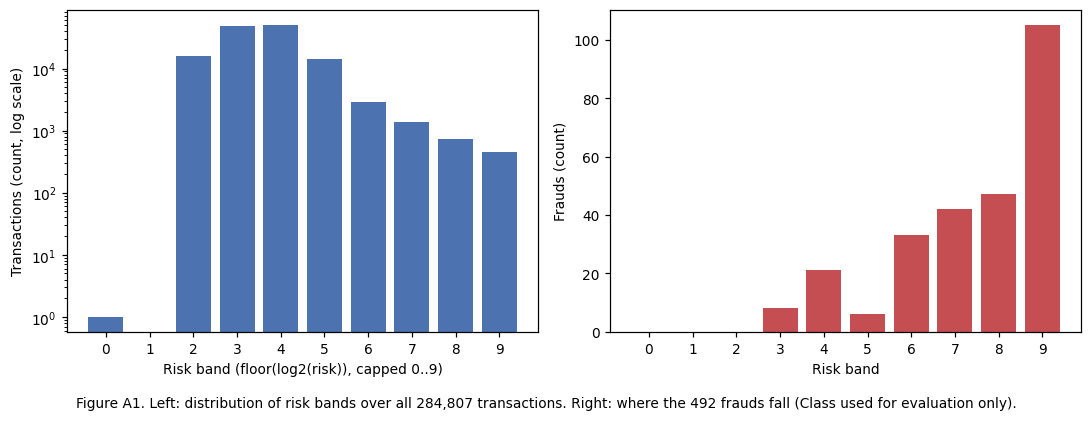

In [7]:
# Problem A - know your data
band, amount, tm, isf = F["band"], F["amount"], F["time"], F["is_fraud"]
counts = np.bincount(band, minlength=10); fr = np.bincount(band[isf == 1], minlength=10)
tabA = pd.DataFrame({"band": range(10), "transactions": counts, "share_%": (100 * counts / N_FULL).round(2),
                     "frauds": fr, "share_of_frauds_%": (100 * fr / fr.sum()).round(2),
                     "fraud_rate_%": (100 * fr / np.maximum(counts, 1)).round(3)})
print("RISK BANDS (full file)"); display(tabA) if "display" in globals() else print(tabA)
print(f"\nrisk score: min {F['risk'].min():.3f}, median {np.median(F['risk']):.3f}, max {F['risk'].max():.1f}; populated bands = {int((counts>0).sum())} of 10")

vc = pd.Series(amount).value_counts()
print(f"\nAMOUNT: {vc.size} distinct values; top-10 most frequent values hold {100*vc.head(10).sum()/N_FULL:.2f}% of all transactions")
print(vc.head(10).rename("count").to_frame().assign(**{"share_%": (100 * vc.head(10) / N_FULL).round(2)}).rename_axis("Amount"))
print(f"TIME: {len(np.unique(tm))} distinct values; adjacent equal-Time pairs: {int((np.diff(tm)==0).sum())}")
print(f"\nFRAUDS: {int(isf.sum())} of {N_FULL} ({100*isf.mean():.3f}%)")

# which Section 3.4 properties does the raw file already have?  (no sorting used: pair tests + patience LIS)
keys_raw = [r[0] for r in _records(range(N_FULL))]
adj_asc = sum(1 for i in range(N_FULL - 1) if keys_raw[i] < keys_raw[i + 1]) / (N_FULL - 1)
rr = np.random.default_rng(SEED); P = 400_000
ii = rr.integers(0, N_FULL, P); jj = rr.integers(0, N_FULL, P); lo_, hi_ = np.minimum(ii, jj), np.maximum(ii, jj); ok_ = lo_ != hi_
inv_frac = float(np.mean([keys_raw[a] > keys_raw[b] for a, b in zip(lo_[ok_], hi_[ok_])]))
oop_raw = (N_FULL - lis_len(keys_raw)) / N_FULL
print("\nSECTION 3.4 PROPERTIES OF THE RAW FILE")
print(f"  C1 Arrival      : Time non-decreasing = {bool(np.all(np.diff(tm) >= 0))} -> the raw file IS C1 by construction")
print(f"  C3 Pre-ranked   : adjacent pairs already in triage order = {100*adj_asc:.1f}%  (a ranked file would show 100%)")
print(f"                    sampled random pairs (i<j) out of order = {100*inv_frac:.1f}%  (ranked: 0%, random: ~50%, reversed: 100%)")
print(f"  C4 Reverse      : adjacent pairs in reverse order = {100*(1-adj_asc):.1f}%  (a reversed file would show 100%)")
print(f"  C5 Nearly ranked: records outside the longest ranked subsequence = {100*oop_raw:.1f}%  (C5 is defined as ~1%)")
print(f"  C6 Band-only    : only {int((counts>0).sum())} distinct band values over {N_FULL} rows -> massive ties under a band-only key")
verdict = "unordered with respect to the triage key (close to random)" if 0.3 < inv_frac < 0.7 else "partly ordered"
print(f"  => Apart from being in Time order (C1), the raw file is {verdict}: it is NOT pre-ranked, reverse-ranked or nearly ranked.")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(range(10), counts, color="#4C72B0"); ax[0].set_yscale("log")
ax[0].set_xlabel("Risk band (floor(log2(risk)), capped 0..9)"); ax[0].set_ylabel("Transactions (count, log scale)"); ax[0].set_xticks(range(10))
ax[1].bar(range(10), fr, color="#C44E52"); ax[1].set_xlabel("Risk band"); ax[1].set_ylabel("Frauds (count)"); ax[1].set_xticks(range(10))
fig.text(0.5, -0.04, "Figure A1. Left: distribution of risk bands over all 284,807 transactions. Right: where the 492 frauds fall (Class used for evaluation only).", ha="center")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "fig_A1_bands.png"), bbox_inches="tight"); plt.show()
tabA.to_csv(os.path.join(OUT_DIR, "problem_A_band_table.csv"), index=False)

## Problem B — the contenders (all written by hand, no built-in sort inside)
* Every full sort sorts a list **in place** and returns `(comparisons, moves)`.
* **Naive Quick Sort** = last element as pivot, Lomuto partition. **Hardened Quick Sort** = random pivot + three-way (Dijkstra) partition, so it survives sorted input *and* heavy ties.
* **Recursion depth:** naive Quick Sort recurses ~n deep on C3, C4 and C6 and would crash Python's recursion limit. Both quicksorts are therefore written **iteratively with an explicit stack** (the smaller part is processed first, so the stack stays O(log n)). Run time is still Θ(n²) for the naive one on those inputs — that is the point of the experiment.
* **DNF rule:** the slow algorithms check the clock every few partitions / insertions and raise `DNF` once a single run passes `TIME_LIMIT`.
* **Top-K:** (a) full Merge Sort + slice, (b) size-K heap (root = the *worst* record kept, i.e. a min-heap on priority), (c) bounded insertion buffer of size K.

In [8]:
# The algorithms
class DNF(Exception): pass
DEADLINE = float("inf")          # set by time_call(); contenders that can be slow check it

def insertion_sort(a):                                   # stable, in place, O(1) extra
    cmp = mv = 0
    for i in range(1, len(a)):
        if not (i & 63) and perf_counter() > DEADLINE: raise DNF
        x = a[i]; xk = x[0]; j = i - 1
        while j >= 0:
            cmp += 1
            if xk < a[j][0]:
                a[j + 1] = a[j]; mv += 1; j -= 1
            else:
                break
        if j + 1 != i:
            a[j + 1] = x; mv += 1
    return cmp, mv

def merge_sort(a):                                       # stable, top-down, O(n) extra (copy of the left half)
    cmp = mv = 0
    def rec(lo, hi):
        nonlocal cmp, mv
        if hi - lo < 2: return
        mid = (lo + hi) // 2
        rec(lo, mid); rec(mid, hi)
        left = a[lo:mid]; nl = mid - lo; mv += nl        # copy left half out (counted as moves)
        i = 0; j = mid; k = lo
        while i < nl and j < hi:
            cmp += 1
            if a[j][0] < left[i][0]:
                a[k] = a[j]; j += 1
            else:                                        # ties take the left element -> stable
                a[k] = left[i]; i += 1
            k += 1; mv += 1
        while i < nl:
            a[k] = left[i]; i += 1; k += 1; mv += 1      # leftover right elements are already in place
    rec(0, len(a))
    return cmp, mv

def quick_naive(a):                                      # last element pivot, Lomuto, iterative, NOT stable
    cmp = mv = calls = 0
    stack = [(0, len(a) - 1)] if len(a) > 1 else []
    while stack:
        lo, hi = stack.pop(); calls += 1
        if hi - lo > 2000 or not (calls & 63):
            if perf_counter() > DEADLINE: raise DNF
        pk = a[hi][0]; i = lo
        for j in range(lo, hi):
            cmp += 1
            if a[j][0] < pk:
                if i != j:
                    a[i], a[j] = a[j], a[i]; mv += 2
                i += 1
        if i != hi:
            a[i], a[hi] = a[hi], a[i]; mv += 2
        ls, rs = i - lo, hi - i                          # sizes of left / right part (pivot excluded)
        if ls >= rs:                                     # push the larger part first -> smaller part is popped first
            if ls > 1: stack.append((lo, i - 1))
            if rs > 1: stack.append((i + 1, hi))
        else:
            if rs > 1: stack.append((i + 1, hi))
            if ls > 1: stack.append((lo, i - 1))
    return cmp, mv

def quick_hardened(a):                                   # random pivot + 3-way partition, iterative, NOT stable
    rnd = random.Random(SEED); cmp = mv = calls = 0
    stack = [(0, len(a) - 1)] if len(a) > 1 else []
    while stack:
        lo, hi = stack.pop(); calls += 1
        if not (calls & 63) and perf_counter() > DEADLINE: raise DNF
        p = rnd.randint(lo, hi)
        if p != lo:
            a[lo], a[p] = a[p], a[lo]; mv += 2
        pk = a[lo][0]; lt = lo; i = lo + 1; gt = hi      # a[lo..lt-1] < pk, a[lt..i-1] == pk, a[gt+1..hi] > pk
        while i <= gt:
            k = a[i][0]; cmp += 1
            if k < pk:
                a[lt], a[i] = a[i], a[lt]; mv += 2; lt += 1; i += 1
            else:
                cmp += 1
                if pk < k:
                    if i != gt:
                        a[i], a[gt] = a[gt], a[i]; mv += 2
                    gt -= 1
                else:
                    i += 1
        ls, rs = lt - lo, hi - gt
        if ls >= rs:
            if ls > 1: stack.append((lo, lt - 1))
            if rs > 1: stack.append((gt + 1, hi))
        else:
            if rs > 1: stack.append((gt + 1, hi))
            if ls > 1: stack.append((lo, lt - 1))
    return cmp, mv

def _sift_down(a, i, end):
    """Max-heap on key (root = largest key = LAST in triage order). Returns (comparisons, moves)."""
    x = a[i]; xk = x[0]; i0 = i; cmp = mv = 0
    while True:
        c = 2 * i + 1
        if c >= end: break
        if c + 1 < end:
            cmp += 1
            if a[c][0] < a[c + 1][0]: c += 1
        cmp += 1
        if xk < a[c][0]:
            a[i] = a[c]; mv += 1; i = c
        else:
            break
    if i != i0:
        a[i] = x; mv += 1
    return cmp, mv

def heap_sort(a):                                        # in place, O(1) extra, NOT stable
    n = len(a); cmp = mv = 0
    for s in range(n // 2 - 1, -1, -1):                  # Floyd build: O(n)
        c, m = _sift_down(a, s, n); cmp += c; mv += m
    for end in range(n - 1, 0, -1):
        a[0], a[end] = a[end], a[0]; mv += 2
        c, m = _sift_down(a, 0, end); cmp += c; mv += m
    return cmp, mv

def heap_feed(h, K, items):
    """Feed records into a size-K heap whose root is the WORST record kept (min-heap on priority)."""
    cmp = mv = 0
    for x in items:
        if len(h) < K:                                   # not full yet: push with sift-up
            h.append(x); mv += 1; j = len(h) - 1; xk = x[0]; last = j
            while j > 0:
                p = (j - 1) // 2; cmp += 1
                if h[p][0] < xk:
                    h[j] = h[p]; mv += 1; j = p
                else:
                    break
            if j != last:
                h[j] = x; mv += 1
        else:
            cmp += 1
            if x[0] < h[0][0]:                           # better than the worst kept record -> replace it
                h[0] = x; mv += 1
                c, m = _sift_down(h, 0, K); cmp += c; mv += m
    return cmp, mv

# Top-K methods.  Signature (a, K) -> (top_list_in_triage_order, comparisons, moves)
def topk_fullsort(a, K):                                 # (a) full Merge Sort then take the first K (sorts the given copy)
    c, m = merge_sort(a)
    return a[:K], c, m

def topk_heap(a, K):                                     # (b) size-K heap
    n = len(a)
    if K >= n:
        b = list(a); c, m = heap_sort(b); return b, c, m
    h = a[:K]; cmp = 0; mv = K
    for s in range(K // 2 - 1, -1, -1):
        c, m = _sift_down(h, s, K); cmp += c; mv += m
    c, m = heap_feed(h, K, itertools.islice(a, K, None)); cmp += c; mv += m
    c, m = heap_sort(h); cmp += c; mv += m               # put the K survivors in triage order
    return h, cmp, mv

def topk_buffer(a, K):                                   # (c) bounded insertion buffer of size K (sorted, best first)
    n = len(a)
    if K >= n:
        b = list(a); c, m = insertion_sort(b); return b, c, m
    buf = [None] * K; size = 0; cmp = mv = 0
    for t, x in enumerate(a):
        if not (t & 255) and perf_counter() > DEADLINE: raise DNF
        xk = x[0]
        if size == K:
            cmp += 1
            if not (xk < buf[K - 1][0]): continue        # not better than the worst kept record
            j = K - 2                                    # slot K-1 (the dropped record) gets overwritten
        else:
            j = size - 1; size += 1
        while j >= 0:
            cmp += 1
            if xk < buf[j][0]:
                buf[j + 1] = buf[j]; mv += 1; j -= 1
            else:
                break
        buf[j + 1] = x; mv += 1
    return buf, cmp, mv

def merge_topk(cur, new, K):
    """Merge two ranked lists, stop after K outputs. Returns (list, comparisons, moves)."""
    i = j = cmp = mv = 0; out = []; nc, nn = len(cur), len(new)
    while len(out) < K and i < nc and j < nn:
        cmp += 1
        if new[j][0] < cur[i][0]: out.append(new[j]); j += 1
        else: out.append(cur[i]); i += 1
        mv += 1
    while len(out) < K and i < nc: out.append(cur[i]); i += 1; mv += 1
    while len(out) < K and j < nn: out.append(new[j]); j += 1; mv += 1
    return out, cmp, mv

FULL_SORTS = {"Insertion Sort": insertion_sort, "Merge Sort": merge_sort, "Naive Quick Sort": quick_naive,
              "Hardened Quick Sort": quick_hardened, "Heap Sort": heap_sort}
STABLE    = {"Insertion Sort": True, "Merge Sort": True, "Naive Quick Sort": False, "Hardened Quick Sort": False, "Heap Sort": False}
EXTRA_MEM = {"Insertion Sort": "O(1)", "Merge Sort": "O(n)", "Naive Quick Sort": "O(log n) stack (smaller part first)",
             "Hardened Quick Sort": "O(log n) stack", "Heap Sort": "O(1)"}
TOPK_METHODS = {"(a) Full sort + slice": topk_fullsort, "(b) Size-K heap": topk_heap, "(c) Insertion buffer": topk_buffer}
COLORS = {"Insertion Sort": "#C44E52", "Merge Sort": "#4C72B0", "Naive Quick Sort": "#DD8452", "Hardened Quick Sort": "#55A868", "Heap Sort": "#8172B3",
          "(a) Full sort + slice": "#4C72B0", "(b) Size-K heap": "#55A868", "(c) Insertion buffer": "#DD8452"}
print("contenders ready:", ", ".join(FULL_SORTS), "| top-K:", ", ".join(TOPK_METHODS))

contenders ready: Insertion Sort, Merge Sort, Naive Quick Sort, Hardened Quick Sort, Heap Sort | top-K: (a) Full sort + slice, (b) Size-K heap, (c) Insertion buffer


In [9]:
# Unit tests (edge cases)
def same_as_ref(out, ref, exact):
    if exact: return out == ref
    return [r[0] for r in out] == [r[0] for r in ref] and sorted(r[1] for r in out) == sorted(r[1] for r in ref)

def run_unit_tests():
    rnd = random.Random(1)
    cases = {"empty": [], "single record": [((5,), 1)], "two records": [((2,), 1), ((1,), 2)],
             "all-equal keys": [((7,), i) for i in range(1, 301)],
             "duplicate-heavy (5 keys)": [((rnd.randint(0, 4),), i) for i in range(1, 601)],
             "distinct random": [((rnd.random(),), i) for i in range(1, 601)],
             "already sorted": [((i,), i) for i in range(1, 401)], "reverse sorted": [((-i,), i) for i in range(1, 401)]}
    rows, ok_all = [], True
    for cname, data in cases.items():
        ref = sorted(data, key=lambda r: r[0]); tie = len({r[0] for r in data}) < len(data)
        for name, fn in FULL_SORTS.items():
            out = list(data); fn(out)
            ok = same_as_ref(out, ref, exact=(STABLE[name] or not tie)); ok_all &= ok
            rows.append((cname, name, "PASS" if ok else "FAIL"))
        for K_ in [1, 5, 50, len(data) - 1, len(data), len(data) + 7]:
            if K_ < 1: continue
            for mname, fn in TOPK_METHODS.items():
                out = fn(list(data), K_)[0]
                if tie and mname == "(b) Size-K heap":      # the heap is not stable: with ties only the key sequence must match
                    ok = [r[0] for r in out] == [r[0] for r in ref[:K_]]
                else:
                    ok = out == ref[:K_]
                ok_all &= ok; rows.append((cname, f"{mname} K={K_}", "PASS" if ok else "FAIL"))
    t = pd.DataFrame(rows, columns=["input", "contender", "result"])
    print(t.groupby("result").size().to_string()); print("failures:", t[t.result == "FAIL"].to_string() if (t.result == "FAIL").any() else "none")
    assert ok_all, "unit tests failed"
    return t
_ = run_unit_tests()
print("All edge-case tests passed (empty, single, all-equal, duplicate-heavy, sorted, reverse, Top-K with K>=n).")
print("Correctness on every condition and size is checked against sorted() inside every benchmark run (column 'correct' in results.csv).")

result
PASS    175
failures: none
All edge-case tests passed (empty, single, all-equal, duplicate-heavy, sorted, reverse, Top-K with K>=n).
Correctness on every condition and size is checked against sorted() inside every benchmark run (column 'correct' in results.csv).


In [10]:
# Benchmark harness + results.csv
COLS = ["problem", "contender", "cond", "n", "K", "window", "idx", "status", "runs", "time_s", "comparisons", "moves", "correct", "peak_bytes", "note"]
def _k(v): return "" if v is None or (isinstance(v, float) and math.isnan(v)) else str(v)
class Store:
    """Append-only results.csv. Every finished measurement is written immediately, so a Colab disconnect loses nothing."""
    def __init__(self, path):
        self.path = path; self.keys = set(); self.dnf = set()
        if os.path.exists(path):
            for r in csv.DictReader(open(path)):
                self.keys.add(self._key(r))
                if r["status"].startswith("DNF"): self.dnf.add((r["problem"], r["contender"], r["cond"], int(r["n"] or 0)))
        else:
            with open(path, "w", newline="") as f: csv.writer(f).writerow(COLS)
    @staticmethod
    def _key(r): return "|".join(_k(r.get(c)) for c in ("problem", "contender", "cond", "n", "K", "window", "idx"))
    def has(self, **kw): return self._key(kw) in self.keys
    def add(self, **row):
        row = {c: row.get(c, "") for c in COLS}
        for c in ("time_s",):
            if isinstance(row[c], float): row[c] = f"{row[c]:.6f}"
        with open(self.path, "a", newline="") as f: csv.writer(f).writerow([row[c] for c in COLS])
        self.keys.add(self._key(row))
        if str(row["status"]).startswith("DNF"): self.dnf.add((row["problem"], row["contender"], row["cond"], int(row["n"] or 0)))
    def df(self):
        d = pd.read_csv(self.path)
        for c in ("n", "K", "window", "idx", "runs", "time_s", "comparisons", "moves", "peak_bytes"): d[c] = pd.to_numeric(d[c], errors="coerce")
        d["status"] = d["status"].fillna(""); d["note"] = d["note"].fillna(""); d["cond"] = d["cond"].fillna("")
        return d
STORE = Store(os.path.join(OUT_DIR, "results.csv"))
print("results file:", STORE.path, "| rows already stored:", len(STORE.keys))

def time_call(fn, data, limit, *args):
    """Fresh copy of the input -> run fn once -> (seconds, return value, the working copy) or None on DNF."""
    global DEADLINE
    a = list(data)
    gc.collect(); gc.disable()
    DEADLINE = perf_counter() + limit
    try:
        t0 = perf_counter(); ret = fn(a, *args); t = perf_counter() - t0
        return t, ret, a
    except DNF:
        return None
    finally:
        DEADLINE = float("inf"); gc.enable()

def is_correct(out, cond, n, stable):
    ref = get_ref(cond, n)
    if len(out) != len(ref): return False
    return same_as_ref(out, ref, exact=(cond != "C6" or stable))      # C6 is not a total order: unstable sorts only need the same band sequence

def bench(problem, label, fn, cond, n, runs, limit, kind="sort", K_=None, check=None, extra_note=""):
    """Median of `runs` timed runs on fresh copies. Returns the stored row dict."""
    data = get_input(cond, n); times = []; first = None
    args = (K_,) if kind == "topk" else ()
    for r in range(runs):
        res = time_call(fn, data, limit, *args)
        if res is None:
            row = dict(problem=problem, contender=label, cond=cond, n=n, K=K_, status="DNF", runs=len(times) + 1,
                       note=f"a single run exceeded {limit}s" + (f" (after {len(times)} completed runs)" if times else "") + extra_note)
            STORE.add(**row); return row
        t, ret, out = res; times.append(t)
        if first is None:
            if kind == "sort": cmp, mv = ret; correct = is_correct(out, cond, n, STABLE.get(label, False))
            else:
                top, cmp, mv = ret; correct = (check(top) if check else True)
            first = (cmp, mv, correct)
    row = dict(problem=problem, contender=label, cond=cond, n=n, K=K_, status="OK", runs=len(times), time_s=statistics.median(times),
               comparisons=first[0], moves=first[1], correct=first[2], note=extra_note + " | all runs (s): " + ";".join(f"{x:.4f}" for x in times))
    STORE.add(**row); return row

def fmt_t(t): return f"{t:.3f}s" if t < 100 else f"{t:.0f}s"
print("harness ready. Single run limit (DNF) =", TIME_LIMIT, "s; runs per measurement =", RUNS)

results file: A2_results_quick/results.csv | rows already stored: 0
harness ready. Single run limit (DNF) = 60.0 s; runs per measurement = 5


## Prediction log — write it BEFORE running the tournament
The assignment caps you at **40 %** if the prediction log is empty or vague, and it is graded for being written *before* the results exist.
The cell below holds a **draft** based on the theory. **Edit it in your own words** (you will be asked to defend it in the viva), then run the cell — it saves the text with a timestamp to `prediction_log.txt`. The tournament cell refuses to run until the log has been saved.
Afterwards, a later cell prints what actually happened so you can fill in *"what I got wrong"*.

In [11]:
# Prediction log (edit, then run)
PRED_FILE = os.path.join(OUT_DIR, "prediction_log.txt")
PREDICTIONS = """
[C] FULL RANKING TOURNAMENT - predictions written before the run
(DRAFT - rewrite in your own words and adjust to what you believe)

C1 Arrival (file order, essentially random with respect to the triage key):
  Winner: Merge Sort (about n*log2(n) - 1.25n comparisons, sequential access, no bad case).
  Loser: Insertion Sort (about n^2/4 comparisons AND n^2/4 moves, so it does not finish for n >= 100,000).
  Why: the raw file is not ordered by band/Amount (Problem A), so insertion sees ~n^2/4 inversions.
C2 Shuffled: same as C1. Naive Quick Sort should be close to Merge Sort here (random order -> balanced splits, ~1.39 n log2 n comparisons).
C3 Pre-ranked:
  Winner: Insertion Sort (n-1 comparisons, 0 moves, Theta(n)).
  Loser: Naive Quick Sort (last-element pivot on sorted input -> splits of size 0 and n-1 -> Theta(n^2)); expect DNF for n >= 100,000.
C4 Reverse-ranked:
  Winner: Merge Sort or Hardened Quick Sort (n log n shapes). Loser: Insertion Sort (n(n-1)/2 comparisons and moves, its worst case).
  Naive Quick Sort is also quadratic on reversed input but with far fewer moves than Insertion.
C5 Nearly ranked (1% of records moved):
  I (inversions) ~ m*n/3 with m = 0.01n, so Insertion costs ~ n + 0.0033 n^2.
  Prediction: Insertion Sort wins only at small n (about n <= 3,000: cost n + 0.0033n^2 < n log2 n) and loses to Merge Sort at n = 10,000 and above.
  Loser at large n: Naive Quick Sort (nearly sorted -> nearly worst-case splits).
C6 Band-only key (only 8 distinct values -> huge tie groups):
  Winner: Hardened Quick Sort (three-way partition puts all equal keys in place at once: ~ n * (small constant) comparisons).
  Loser: Naive Quick Sort or Insertion Sort - Lomuto with strict '<' sends every tie to one side, giving about sum(m_i^2)/2 comparisons for group sizes m_i
  (that is ~0.16 n^2 here); I expect Naive Quick Sort to DNF at n >= 100,000.
Heap Sort: never the winner (about 2 n log2 n comparisons and poor locality), never the loser on shuffled data; it should be the slowest of the n log n sorts.

[D] TOP-K (to be completed before running Problem D) - draft:
  Heap (b) should win for small K; the insertion buffer (c) should win only for very small K (K <= ~20) and become hopeless as K grows (K^2 ln(n/K)/2 shifts);
  full sort (a) never wins for K << n but approaches/overtakes the heap as K approaches n/10.
[E] LIVE FEED (draft): size-K heap fed by new records (b) should be cheapest for 1-hour and 10-minute windows; re-ranking everything (a) is Theta(n*w*log n) and should DNF at 10-minute windows.
"""
_DRAFT_SIG = "993500fa1d9c3ad4b26e4e09e33d86e2"       # fingerprint of the unedited draft, so the full run can insist that you wrote your own version
def save_prediction_log(text=None):
    text = (text or PREDICTIONS).strip()
    with open(PRED_FILE, "a") as f:
        f.write(f"\n===== saved {datetime.datetime.now().isoformat(timespec='seconds')} (before running the tournament) =====\n{text}\n")
    print("prediction log saved ->", PRED_FILE)
_saved = open(PRED_FILE).read() if os.path.exists(PRED_FILE) else ""
if PREDICTIONS.strip() not in _saved:
    save_prediction_log()
else:
    print("this version of the prediction log is already saved:", PRED_FILE)
if hashlib.md5(PREDICTIONS.strip().encode()).hexdigest() == _DRAFT_SIG:
    print("\n*** NOTE: this is still the unedited DRAFT. That is fine for MODE='smoke'/'quick', but rewrite it in your own words before the final MODE='full' run. ***")
print(PREDICTIONS.strip()[:700] + ' ...')

prediction log saved -> A2_results_quick/prediction_log.txt

*** NOTE: this is still the unedited DRAFT. That is fine for MODE='smoke'/'quick', but rewrite it in your own words before the final MODE='full' run. ***
[C] FULL RANKING TOURNAMENT - predictions written before the run
(DRAFT - rewrite in your own words and adjust to what you believe)

C1 Arrival (file order, essentially random with respect to the triage key):
  Winner: Merge Sort (about n*log2(n) - 1.25n comparisons, sequential access, no bad case).
  Loser: Insertion Sort (about n^2/4 comparisons AND n^2/4 moves, so it does not finish for n >= 100,000).
  Why: the raw file is not ordered by band/Amount (Problem A), so insertion sees ~n^2/4 inversions.
C2 Shuffled: same as C1. Naive Quick Sort should be close to Merge Sort here (random order -> balanced splits, ~1.39 n log2 n comparisons).
C3 Pre-ranked:
  Winner: Insertion Sort (n-1 compari ...


## Problem C — the full ranking tournament
Five contenders × six conditions × the sizes of your `MODE`. Each cell of the grid is the **median of `RUNS` runs** on fresh copies; any single run over `TIME_LIMIT` is recorded as **DNF**. The first run of every cell is also checked for **exact equality with `sorted()`** (column `correct`).

In [12]:
# Problem C - run the tournament
# Ensure preceding setup variables/functions are available in the local namespace
if "get_input" not in globals() or "get_ref" not in globals():
    raise NameError("Setup functions are missing. Please run cells c01, c02, and c03 first before running the tournament.")

if not SKIP_LOG_CHECK:
    assert "[C]" in open(PRED_FILE).read(), "Write and save your prediction log first (cell 8)."
    if MODE == "full" and hashlib.md5(PREDICTIONS.strip().encode()).hexdigest() == _DRAFT_SIG:
        raise RuntimeError("Edit the prediction log in cell 8 (rewrite it in your own words) and run that cell again before the full run.")
def run_tournament(sizes=SIZES, conds=CONDS):
    dnf_seen = set()
    for (p, name, cond, n_) in STORE.dnf:
        if p == "C": dnf_seen.add((name, cond, n_))
    t_start = perf_counter()
    for n in sizes:
        for cond in conds:
            for name, fn in FULL_SORTS.items():
                key = dict(problem="C", contender=name, cond=cond, n=n, K=None, window=None)
                if STORE.has(**key): continue
                if INFER_DNF and any(nm == name and cd == cond and n_ < n for (nm, cd, n_) in dnf_seen):
                    STORE.add(**key, status="DNF_inferred", note="not run: a smaller n already exceeded the time limit (quadratic growth)")
                    print(f"n={n:>7} {cond} {name:<20} DNF (inferred)"); continue
                row = bench("C", name, fn, cond, n, RUNS, TIME_LIMIT)
                if row["status"] == "DNF": dnf_seen.add((name, cond, n))
                msg = "DNF" if row["status"] == "DNF" else f"{fmt_t(row['time_s']):>9}  cmp={row['comparisons']:>13,}  moves={row['moves']:>13,}  correct={row['correct']}"
                print(f"n={n:>7} {cond} {name:<20} {msg}   [elapsed {perf_counter()-t_start:6.0f}s]", flush=True)
run_tournament()
DF = STORE.df(); C = DF[(DF.problem == "C")]
bad = C[(C.status == "OK") & (C.correct.astype(str) != "True")]
print("\nincorrect outputs:", "none - every finished run matches sorted() exactly (C6: stable sorts exactly, unstable ones band-by-band)" if bad.empty else bad)

n=   1000 C1 Insertion Sort          0.050s  cmp=      229,467  moves=      229,466  correct=True   [elapsed      1s]
n=   1000 C1 Merge Sort              0.003s  cmp=        8,657  moves=       14,192  correct=True   [elapsed      1s]
n=   1000 C1 Naive Quick Sort        0.003s  cmp=       10,777  moves=       11,290  correct=True   [elapsed      2s]
n=   1000 C1 Hardened Quick Sort     0.005s  cmp=       15,516  moves=       20,982  correct=True   [elapsed      2s]
n=   1000 C1 Heap Sort               0.004s  cmp=       16,887  moves=       11,514  correct=True   [elapsed      3s]
n=   1000 C2 Insertion Sort          0.060s  cmp=      249,243  moves=      249,245  correct=True   [elapsed      3s]
n=   1000 C2 Merge Sort              0.003s  cmp=        8,680  moves=       14,239  correct=True   [elapsed      4s]
n=   1000 C2 Naive Quick Sort        0.002s  cmp=       10,212  moves=        9,088  correct=True   [elapsed      4s]
n=   1000 C2 Hardened Quick Sort     0.008s  cmp=       

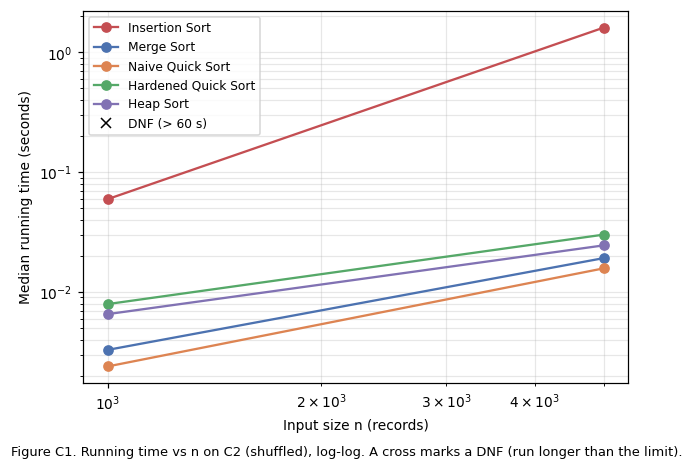

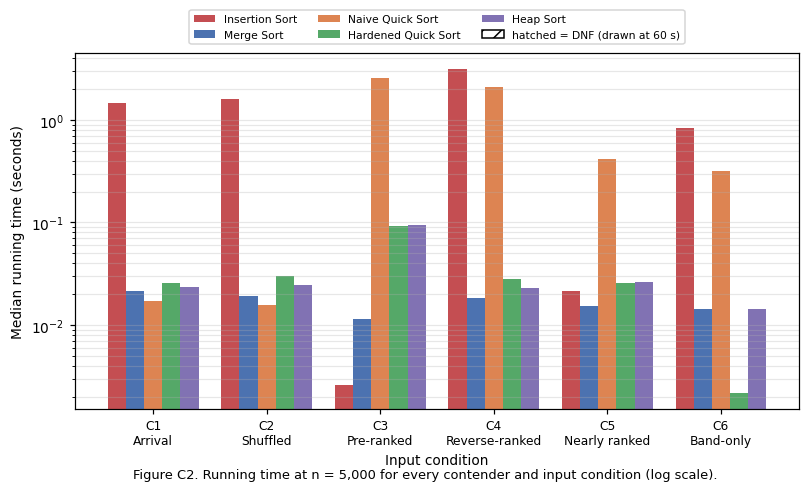

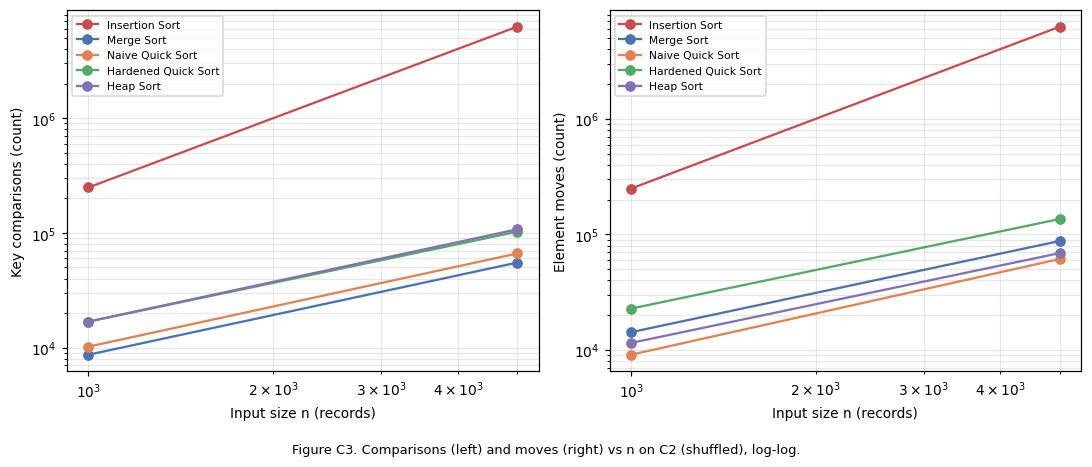

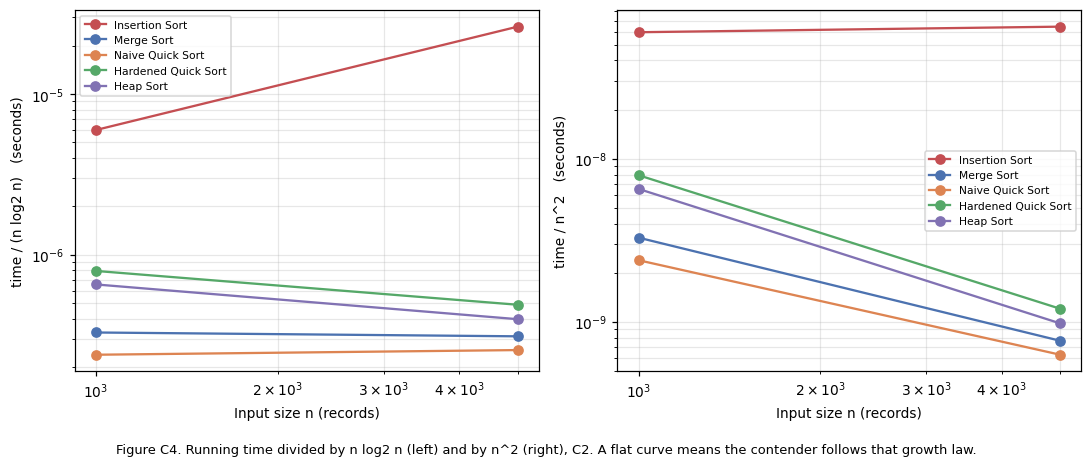


TABLE C5 - summary at n = 5,000
          contender         condition  time_s  comparisons    moves                        extra memory stable
     Insertion Sort        C1 Arrival  1.4493      5698515  5698518                                O(1)    yes
     Insertion Sort       C2 Shuffled  1.6103      6283147  6283148                                O(1)    yes
     Insertion Sort     C3 Pre-ranked  0.0026         4999        0                                O(1)    yes
     Insertion Sort C4 Reverse-ranked  3.1270     12497500 12502499                                O(1)    yes
     Insertion Sort  C5 Nearly ranked  0.0212        73733    73614                                O(1)    yes
     Insertion Sort      C6 Band-only  0.8432      3832425  3831866                                O(1)    yes
         Merge Sort        C1 Arrival  0.0214        55112    87659                                O(n)    yes
         Merge Sort       C2 Shuffled  0.0192        55183    87766            

In [13]:
# Problem C - figures and tables
DF = STORE.df(); C = DF[DF.problem == "C"].copy()
def ok_rows(d, name): return d[(d.contender == name) & (d.status == "OK")].sort_values("n")
dnf_proxy = Line2D([0], [0], marker="x", color="k", linestyle="None", label=f"DNF (> {TIME_LIMIT:g} s)")
def caption(fig, text): fig.text(0.5, -0.04, text, ha="center", fontsize=8.5)

# Figure C1: time vs n, C2, log-log
d = C[C.cond == "C2"]; fig, ax = plt.subplots(figsize=(6.4, 4.4))
for name in FULL_SORTS:
    x = ok_rows(d, name); ax.plot(x.n, x.time_s, marker="o", color=COLORS[name], label=name)
    dn = d[(d.contender == name) & d.status.str.startswith("DNF")]
    ax.scatter(dn.n, [TIME_LIMIT] * len(dn), marker="x", color=COLORS[name], s=70)
h, l = ax.get_legend_handles_labels(); ax.legend(h + [dnf_proxy], l + [dnf_proxy.get_label()], fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Input size n (records)"); ax.set_ylabel("Median running time (seconds)"); ax.grid(alpha=.3, which="both")
caption(fig, "Figure C1. Running time vs n on C2 (shuffled), log-log. A cross marks a DNF (run longer than the limit).")
fig.savefig(os.path.join(OUT_DIR, "fig_C1_time_vs_n_C2.png"), bbox_inches="tight"); plt.show()

# Figure C2: grouped bars at BAR_N across the six conditions
n0 = BAR_N if BAR_N in set(C.n) else int(C.n.max()); d = C[C.n == n0]
fig, ax = plt.subplots(figsize=(8.5, 4.2)); w = 0.16
for k_, name in enumerate(FULL_SORTS):
    ys, hatch = [], []
    for cond in CONDS:
        r = d[(d.contender == name) & (d.cond == cond)]
        if len(r) and r.iloc[0].status == "OK": ys.append(float(r.iloc[0].time_s)); hatch.append(False)
        else: ys.append(TIME_LIMIT); hatch.append(True)
    for j, (y, hh) in enumerate(zip(ys, hatch)):
        ax.bar(j + (k_ - 2) * w, y, w, color=COLORS[name], hatch="//" if hh else None, edgecolor="k" if hh else None, label=name if j == 0 else None)
ax.set_yscale("log"); ax.set_xticks(range(6)); ax.set_xticklabels([f"{c}\n{COND_NAME[c]}" for c in CONDS], fontsize=8)
ax.set_xlabel("Input condition"); ax.set_ylabel("Median running time (seconds)"); ax.grid(alpha=.3, axis="y", which="both")
h, l = ax.get_legend_handles_labels(); h.append(plt.Rectangle((0, 0), 1, 1, fill=False, hatch="//")); l.append(f"hatched = DNF (drawn at {TIME_LIMIT:g} s)"); ax.legend(h, l, fontsize=7, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.01))
caption(fig, f"Figure C2. Running time at n = {n0:,} for every contender and input condition (log scale).")
fig.savefig(os.path.join(OUT_DIR, "fig_C2_conditions_bars.png"), bbox_inches="tight"); plt.show()

# Figure C3: comparisons and moves vs n on C2
d = C[C.cond == "C2"]; fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a_, col, yl in [(ax[0], "comparisons", "Key comparisons (count)"), (ax[1], "moves", "Element moves (count)")]:
    for name in FULL_SORTS:
        x = ok_rows(d, name); a_.plot(x.n, x[col], marker="o", color=COLORS[name], label=name)
    a_.set_xscale("log"); a_.set_yscale("log"); a_.set_xlabel("Input size n (records)"); a_.set_ylabel(yl); a_.grid(alpha=.3, which="both"); a_.legend(fontsize=7)
caption(fig, "Figure C3. Comparisons (left) and moves (right) vs n on C2 (shuffled), log-log.")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "fig_C3_counts_vs_n_C2.png"), bbox_inches="tight"); plt.show()

# Figure C4: time/(n log2 n) and time/n^2
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a_, f_, yl in [(ax[0], lambda x: x.time_s / (x.n * np.log2(x.n)), "time / (n log2 n)   (seconds)"), (ax[1], lambda x: x.time_s / x.n ** 2, "time / n^2   (seconds)")]:
    for name in FULL_SORTS:
        x = ok_rows(C[C.cond == "C2"], name)
        if len(x): a_.plot(x.n, f_(x), marker="o", color=COLORS[name], label=name)
    a_.set_xscale("log"); a_.set_yscale("log"); a_.set_xlabel("Input size n (records)"); a_.set_ylabel(yl); a_.grid(alpha=.3, which="both"); a_.legend(fontsize=7)
caption(fig, "Figure C4. Running time divided by n log2 n (left) and by n^2 (right), C2. A flat curve means the contender follows that growth law.")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "fig_C4_normalised.png"), bbox_inches="tight"); plt.show()

# Table C5: summary for every contender and condition
def summary_table(n):
    rows = []
    for name in FULL_SORTS:
        for cond in CONDS:
            r = C[(C.contender == name) & (C.cond == cond) & (C.n == n)]
            if r.empty: continue
            r = r.iloc[0]; ok = r.status == "OK"
            rows.append({"contender": name, "condition": f"{cond} {COND_NAME[cond]}", "time_s": round(r.time_s, 4) if ok else r.status,
                         "comparisons": int(r.comparisons) if ok else "-", "moves": int(r.moves) if ok else "-",
                         "extra memory": EXTRA_MEM[name], "stable": "yes" if STABLE[name] else "no"})
    return pd.DataFrame(rows)
for n in sorted({n0, int(C.n.max())}):
    t = summary_table(n); t.to_csv(os.path.join(OUT_DIR, f"table_C5_summary_n{n}.csv"), index=False)
    print(f"\nTABLE C5 - summary at n = {n:,}"); display(t) if "display" in globals() else print(t.to_string(index=False))

In [14]:
# "what did i get wrong?" helper for your prediction log
DF = STORE.df(); C = DF[DF.problem == "C"]
print("OBSERVED winners and losers (use this to fill in the 'what I got wrong' part of your prediction log)\n")
for n in sorted({BAR_N if BAR_N in set(C.n) else int(C.n.max()), int(C.n.max())}):
    print(f"--- n = {n:,} ---")
    for cond in CONDS:
        d = C[(C.n == n) & (C.cond == cond)]
        fin = d[d.status == "OK"].sort_values("time_s")
        dn = d[d.status.str.startswith("DNF")].contender.tolist()
        if fin.empty: print(f"{cond} {COND_NAME[cond]:<15}: everything DNF"); continue
        worst = (dn[0] + " (DNF)") if dn else fin.iloc[-1].contender
        print(f"{cond} {COND_NAME[cond]:<15}: winner = {fin.iloc[0].contender:<20} ({fmt_t(fin.iloc[0].time_s)}) | loser = {worst}" +
              (f" | all DNF: {', '.join(dn)}" if dn else ""))

OBSERVED winners and losers (use this to fill in the 'what I got wrong' part of your prediction log)

--- n = 5,000 ---
C1 Arrival        : winner = Naive Quick Sort     (0.017s) | loser = Insertion Sort
C2 Shuffled       : winner = Naive Quick Sort     (0.016s) | loser = Insertion Sort
C3 Pre-ranked     : winner = Insertion Sort       (0.003s) | loser = Naive Quick Sort
C4 Reverse-ranked : winner = Merge Sort           (0.018s) | loser = Insertion Sort
C5 Nearly ranked  : winner = Merge Sort           (0.015s) | loser = Naive Quick Sort
C6 Band-only      : winner = Hardened Quick Sort  (0.002s) | loser = Insertion Sort


In [15]:
# Extra memory (measured with tracemalloc)
def peak_extra_bytes(fn, data, *args):
    a = list(data); gc.collect()
    tracemalloc.start()
    try:
        fn(a, *args)
        return tracemalloc.get_traced_memory()[1]
    finally:
        tracemalloc.stop()
def run_memory(ns):
    for n in ns:
        for name, fn in FULL_SORTS.items():
            key = dict(problem="C_mem", contender=name, cond="C2", n=n, K=None, window=None)
            if STORE.has(**key): continue
            if INFER_DNF and any(p == "C" and nm == name and cd == "C2" and n_ <= n for (p, nm, cd, n_) in STORE.dnf):
                STORE.add(**key, status="skipped", note="contender DNFs at this n"); continue
            b = peak_extra_bytes(fn, get_input("C2", n))
            STORE.add(**key, status="OK", peak_bytes=b, note="tracemalloc peak during the sort, input copy excluded")
run_memory(sorted({SIZES[0], BAR_N if BAR_N in SIZES else SIZES[-1], min(100000, SIZES[-1])}))
DF = STORE.df(); M = DF[(DF.problem == "C_mem") & (DF.status == "OK")]
if len(M):
    t = M.pivot_table(index="contender", columns="n", values="peak_bytes").round(0).astype("Int64"); t.columns = [f"n={c:,}  (bytes)" for c in t.columns]
    print("Measured peak extra memory on C2 (bytes):"); display(t) if "display" in globals() else print(t)
    print("Merge Sort grows linearly with n, Heap/Insertion stay at a few hundred bytes, the quicksorts stay tiny (explicit stack only).")

Measured peak extra memory on C2 (bytes):
                     n=1,000  (bytes)  n=5,000  (bytes)
contender                                              
Hardened Quick Sort              4288              4680
Heap Sort                         420               420
Insertion Sort                   4496               328
Merge Sort                       4780             20780
Naive Quick Sort                 1128              1336
Merge Sort grows linearly with n, Heap/Insertion stay at a few hundred bytes, the quicksorts stay tiny (explicit stack only).


In [16]:
# Dnf prediction check (rule 5 of the assignment)
# For every (contender, condition) that DNF'd: predict the missing running times from the largest COMPLETED size using the
# theoretical quadratic law, then CHECK the prediction by actually measuring a smaller-scale run at n = VAL_N.
def dnf_report():
    DF = STORE.df(); C = DF[DF.problem == "C"]; rows = []
    for (name, cond), g in C.groupby(["contender", "cond"]):
        dn = g[g.status.str.startswith("DNF")].sort_values("n")
        if dn.empty: continue
        okk = g[g.status == "OK"].sort_values("n")
        if okk.empty: rows.append({"contender": name, "cond": cond, "largest n completed": "none", "note": "even the smallest size DNF'd"}); continue
        a_n, a_t = int(okk.iloc[-1].n), float(okk.iloc[-1].time_s)
        key = dict(problem="C_val", contender=name, cond=cond, n=VAL_N, K=None, window=None)
        pred_val = a_t * (VAL_N / a_n) ** 2
        if VAL_N > a_n and not STORE.has(**key):
            row = bench("C_val", name, FULL_SORTS[name], cond, VAL_N, 1, TIME_LIMIT, extra_note=f" | predicted {pred_val:.3f}s from n={a_n} with t ~ n^2")
        r = STORE.df(); r = r[(r.problem == "C_val") & (r.contender == name) & (r.cond == cond)]
        meas = float(r.iloc[0].time_s) if len(r) and r.iloc[0].status == "OK" else float("nan")
        rows.append({"contender": name, "cond": cond, "largest n completed": a_n, "time there (s)": round(a_t, 3),
                     f"predicted t(n={VAL_N:,}) (s)": round(pred_val, 3), "measured (s)": round(meas, 3) if meas == meas else "DNF/not run",
                     "error %": round(100 * (meas - pred_val) / pred_val, 1) if meas == meas else "-",
                     "first DNF n": int(dn.iloc[0].n), "predicted time at first DNF n (s)": round(a_t * (int(dn.iloc[0].n) / a_n) ** 2, 1)})
    return pd.DataFrame(rows)
T_dnf = dnf_report().fillna("-")
if T_dnf.empty: print("No contender hit the time limit in this MODE - nothing to predict.")
else:
    display(T_dnf) if "display" in globals() else print(T_dnf.to_string(index=False))
    T_dnf.to_csv(os.path.join(OUT_DIR, "table_C_dnf_predictions.csv"), index=False)
    print("Use this table in the report: largest n completed, the predicted time at the missing point, and how far the smaller-scale check was off.")

No contender hit the time limit in this MODE - nothing to predict.


## Problem D — the shift queue (top-K)
Three ways to produce the first K records of the triage order: **(a)** full Merge Sort then slice, **(b)** size-K heap, **(c)** bounded insertion buffer of size K.
K ∈ {10, 50, **152**, 500, 5,000, n/10}, on C1 and C2. Method (a) does not depend on K (the slice is free), so it is timed once per (n, condition) and the same measurement is stored for every K.
Every result is checked to be **identical** to the first K records of `sorted()`.

In [17]:
# Problem D - run
def d_ks(n):
    return sorted({k for k in [10, 50, K, 500, 5000, n // 10] if 1 <= k < n})
def run_topk():
    t_start = perf_counter(); dnf_seen = set()
    for (p, nm, cd, n_) in STORE.dnf:
        if p == "D": dnf_seen.add((nm, cd, n_))
    for n in D_SIZES:
        for cond in ["C1", "C2"]:
            ref = get_ref(cond, n)
            # (a) once per (n, cond)
            ma = "(a) Full sort + slice"
            ra = None
            for k in d_ks(n):
                key = dict(problem="D", contender=ma, cond=cond, n=n, K=k, window=None)
                if STORE.has(**key): continue
                if ra is None:
                    ra = bench("D", ma, topk_fullsort, cond, n, RUNS, TIME_LIMIT, kind="topk", K_=k, check=lambda top, k=k: top == ref[:k])
                    print(f"n={n:>7} {cond} {ma:<22} K={k:<6} {fmt_t(ra['time_s']) if ra['status']=='OK' else 'DNF':>9}", flush=True)
                else:
                    STORE.add(**key, status=ra["status"], runs=ra["runs"], time_s=ra.get("time_s", ""), comparisons=ra.get("comparisons", ""),
                              moves=ra.get("moves", ""), correct=ra.get("correct", ""), note="same full-sort measurement reused (cost independent of K)")
            for mname in ["(b) Size-K heap", "(c) Insertion buffer"]:
                fn = TOPK_METHODS[mname]
                for k in d_ks(n):
                    key = dict(problem="D", contender=mname, cond=cond, n=n, K=k, window=None)
                    if STORE.has(**key): continue
                    if INFER_DNF and any(nm == mname and cd == cond and n_ == n for (nm, cd, n_) in dnf_seen):   # a smaller K already DNF'd -> larger K will too
                        STORE.add(**key, status="DNF_inferred", note="not run: a smaller K already exceeded the limit at this n"); continue
                    r = bench("D", mname, fn, cond, n, RUNS, TIME_LIMIT, kind="topk", K_=k, check=lambda top, k=k: top == ref[:k])
                    if r["status"] == "DNF": dnf_seen.add((mname, cond, n))
                    print(f"n={n:>7} {cond} {mname:<22} K={k:<6} {fmt_t(r['time_s']) if r['status']=='OK' else 'DNF':>9}   [elapsed {perf_counter()-t_start:5.0f}s]", flush=True)
run_topk()
DF = STORE.df(); D = DF[DF.problem == "D"]
bad = D[(D.status == "OK") & (D.correct.astype(str) != "True")]
print("\nincorrect top-K results:", "none (all identical to sorted()[:K])" if bad.empty else bad)

n=  10000 C1 (a) Full sort + slice  K=10        0.076s
n=  10000 C1 (b) Size-K heap        K=10        0.004s   [elapsed     2s]
n=  10000 C1 (b) Size-K heap        K=50        0.005s   [elapsed     2s]
n=  10000 C1 (b) Size-K heap        K=152       0.008s   [elapsed     3s]
n=  10000 C1 (b) Size-K heap        K=500       0.009s   [elapsed     4s]
n=  10000 C1 (b) Size-K heap        K=1000      0.013s   [elapsed     4s]
n=  10000 C1 (b) Size-K heap        K=5000      0.044s   [elapsed     5s]
n=  10000 C1 (c) Insertion buffer   K=10        0.003s   [elapsed     5s]
n=  10000 C1 (c) Insertion buffer   K=50        0.005s   [elapsed     6s]
n=  10000 C1 (c) Insertion buffer   K=152       0.014s   [elapsed     7s]
n=  10000 C1 (c) Insertion buffer   K=500       0.094s   [elapsed     8s]
n=  10000 C1 (c) Insertion buffer   K=1000      0.276s   [elapsed     9s]
n=  10000 C1 (c) Insertion buffer   K=5000      3.260s   [elapsed    29s]
n=  10000 C2 (a) Full sort + slice  K=10        0.047s
n=

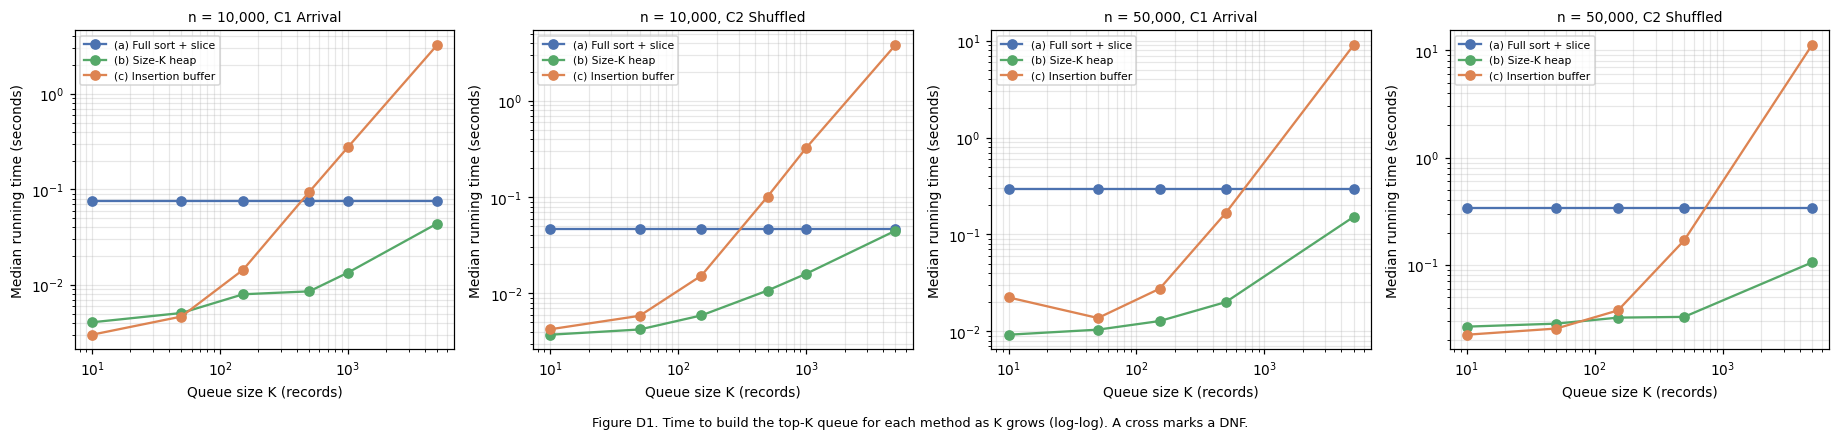

BEST METHOD PER K
    n cond    K         best by time  time_s   best by comparisons
10000   C1   10 (c) Insertion buffer  0.0030       (b) Size-K heap
10000   C1   50 (c) Insertion buffer  0.0047       (b) Size-K heap
10000   C1  152      (b) Size-K heap  0.0080       (b) Size-K heap
10000   C1  500      (b) Size-K heap  0.0086       (b) Size-K heap
10000   C1 1000      (b) Size-K heap  0.0134       (b) Size-K heap
10000   C1 5000      (b) Size-K heap  0.0439 (a) Full sort + slice
10000   C2   10      (b) Size-K heap  0.0037       (b) Size-K heap
10000   C2   50      (b) Size-K heap  0.0042       (b) Size-K heap
10000   C2  152      (b) Size-K heap  0.0059       (b) Size-K heap
10000   C2  500      (b) Size-K heap  0.0107       (b) Size-K heap
10000   C2 1000      (b) Size-K heap  0.0160       (b) Size-K heap
10000   C2 5000      (b) Size-K heap  0.0449 (a) Full sort + slice
50000   C1   10      (b) Size-K heap  0.0092       (b) Size-K heap
50000   C1   50      (b) Size-K heap  0.0104

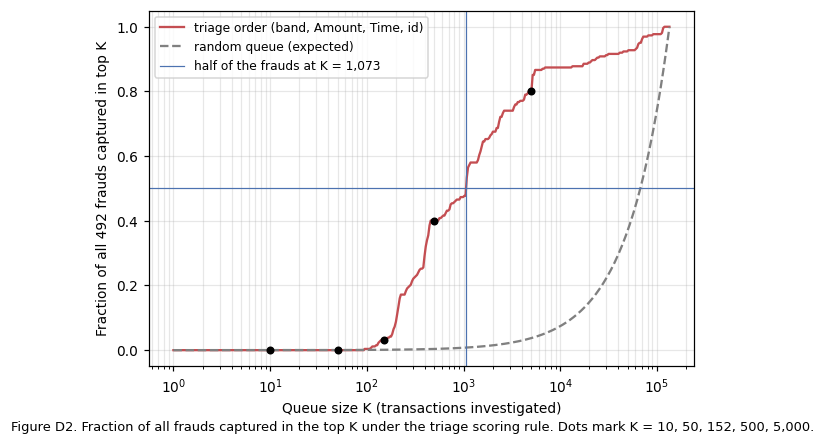

frauds captured: K=10: 0.0, K=50: 0.0, K=152: 8.0 (3.1%), K=500: 105.0, K=5000: 210.0 of 262
SMALLEST K THAT CAPTURES HALF OF THE FRAUDS (>= 131 of 262): K = 1,073  (0.80% of all transactions)


In [18]:
# Problem D - figures, crossovers, fraud capture
DF = STORE.df(); D = DF[DF.problem == "D"].copy()
def caption(fig, text): fig.text(0.5, -0.03, text, ha="center", fontsize=8.5)
combos = [(n, c) for n in D_SIZES for c in ["C1", "C2"]]
fig, axes = plt.subplots(1, len(combos), figsize=(4.2 * len(combos), 3.8), squeeze=False)
for ax, (n, cond) in zip(axes[0], combos):
    for m in TOPK_METHODS:
        x = D[(D.n == n) & (D.cond == cond) & (D.contender == m) & (D.status == "OK")].sort_values("K")
        ax.plot(x.K, x.time_s, marker="o", color=COLORS[m], label=m)
        dn = D[(D.n == n) & (D.cond == cond) & (D.contender == m) & D.status.str.startswith("DNF")]
        ax.scatter(dn.K, [TIME_LIMIT] * len(dn), marker="x", color=COLORS[m], s=70)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"n = {n:,}, {cond} {COND_NAME[cond]}", fontsize=9)
    ax.set_xlabel("Queue size K (records)"); ax.set_ylabel("Median running time (seconds)"); ax.grid(alpha=.3, which="both"); ax.legend(fontsize=7)
caption(fig, "Figure D1. Time to build the top-K queue for each method as K grows (log-log). A cross marks a DNF.")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "fig_D1_time_vs_K.png"), bbox_inches="tight"); plt.show()

# who is best at each K (by time and by comparisons)
rows = []
for (n, cond), g in D[D.status == "OK"].groupby(["n", "cond"]):
    for k, gk in g.groupby("K"):
        rows.append({"n": int(n), "cond": cond, "K": int(k), "best by time": gk.loc[gk.time_s.idxmin()].contender, "time_s": round(gk.time_s.min(), 4),
                     "best by comparisons": gk.loc[gk.comparisons.idxmin()].contender})
BEST = pd.DataFrame(rows).sort_values(["n", "cond", "K"]); print("BEST METHOD PER K"); display(BEST) if "display" in globals() else print(BEST.to_string(index=False))
BEST.to_csv(os.path.join(OUT_DIR, "table_D_best_per_K.csv"), index=False)
print("\nWhere does each method stop being the best choice? -> read the 'best by time' column from small K to large K for each (n, cond).")

# fraction of all frauds captured in the top K  (Class = evaluation only; ranking = triage order of the FULL file)
ref_full = get_ref("C1", N_FULL) if N_FULL in SIZES or True else None
order_ids = np.array([r[1] for r in ref_full]); fr_sorted = F["is_fraud"][order_ids - 1]
cum = np.cumsum(fr_sorted); tot = int(cum[-1]); K_HALF = int(np.searchsorted(cum, int(np.ceil(tot / 2)), side="left") + 1)
fig, ax = plt.subplots(figsize=(6.4, 4.2)); xs = np.unique(np.round(np.logspace(0, np.log10(N_FULL), 400)).astype(int))
ax.plot(xs, cum[xs - 1] / tot, color="#C44E52", label="triage order (band, Amount, Time, id)")
ax.plot(xs, xs / N_FULL, color="grey", linestyle="--", label="random queue (expected)")
for k in [10, 50, K, 500, 5000]: ax.scatter([k], [cum[k - 1] / tot], color="k", zorder=5, s=18)
ax.axhline(0.5, color="#4C72B0", linewidth=.8); ax.axvline(K_HALF, color="#4C72B0", linewidth=.8, label=f"half of the frauds at K = {K_HALF:,}")
ax.set_xscale("log"); ax.set_xlabel("Queue size K (transactions investigated)"); ax.set_ylabel("Fraction of all 492 frauds captured in top K"); ax.grid(alpha=.3, which="both"); ax.legend(fontsize=8)
caption(fig, "Figure D2. Fraction of all frauds captured in the top K under the triage scoring rule. Dots mark K = 10, 50, 152, 500, 5,000.")
fig.savefig(os.path.join(OUT_DIR, "fig_D2_fraud_capture.png"), bbox_inches="tight"); plt.show()
print(f"frauds captured: K=10: {cum[9]}, K=50: {cum[49]}, K={K}: {cum[K-1]} ({100*cum[K-1]/tot:.1f}%), K=500: {cum[499]}, K=5000: {cum[4999]} of {tot}")
print(f"SMALLEST K THAT CAPTURES HALF OF THE FRAUDS (>= {int(np.ceil(tot/2))} of {tot}): K = {K_HALF:,}  ({100*K_HALF/N_FULL:.2f}% of all transactions)")

In [19]:
# Problem D - cost of the "half the frauds" queue
def run_half():
    for n in D_SIZES:
        if K_HALF >= n:
            print(f"n={n:,}: K_half = {K_HALF:,} is not smaller than n - skipped"); continue
        for cond in ["C1", "C2"]:
            ref = get_ref(cond, n)
            for mname, fn in TOPK_METHODS.items():
                key = dict(problem="D_half", contender=mname, cond=cond, n=n, K=K_HALF, window=None)
                if STORE.has(**key): continue
                r = bench("D_half", mname, fn, cond, n, RUNS, TIME_LIMIT, kind="topk", K_=K_HALF, check=lambda top: top == ref[:K_HALF])
                print(f"n={n:>7} {cond} {mname:<22} K={K_HALF:,} {fmt_t(r['time_s']) if r['status']=='OK' else 'DNF':>9}", flush=True)
run_half()
DF = STORE.df(); H = DF[DF.problem == "D_half"][["n", "cond", "contender", "K", "status", "time_s", "comparisons", "moves", "correct"]]
print(f"\nCost of building the queue that captures half the frauds (K = {K_HALF:,}):"); display(H) if "display" in globals() else print(H.to_string(index=False))

n=  10000 C1 (a) Full sort + slice  K=1,073    0.044s
n=  10000 C1 (b) Size-K heap        K=1,073    0.014s
n=  10000 C1 (c) Insertion buffer   K=1,073    0.307s
n=  10000 C2 (a) Full sort + slice  K=1,073    0.045s
n=  10000 C2 (b) Size-K heap        K=1,073    0.017s
n=  10000 C2 (c) Insertion buffer   K=1,073    0.628s
n=  50000 C1 (a) Full sort + slice  K=1,073    0.290s
n=  50000 C1 (b) Size-K heap        K=1,073    0.031s
n=  50000 C1 (c) Insertion buffer   K=1,073    0.616s
n=  50000 C2 (a) Full sort + slice  K=1,073    0.331s
n=  50000 C2 (b) Size-K heap        K=1,073    0.045s
n=  50000 C2 (c) Insertion buffer   K=1,073    0.637s

Cost of building the queue that captures half the frauds (K = 1,073):
    n cond             contender      K status   time_s  comparisons     moves correct
10000   C1 (a) Full sort + slice 1073.0     OK 0.044458     120026.0  190056.0    True
10000   C1       (b) Size-K heap 1073.0     OK 0.014449      61627.0   32871.0    True
10000   C1  (c) Inse

## Problem E — the live feed
The file spans 48 hours. It is split into consecutive windows by `Time` and after each window the top K among **everything seen so far** is published (as a ranked list):
* **(a)** re-rank everything after every window (Merge Sort of all records seen so far),
* **(b)** keep a size-K heap fed only with the new window's records; publish a ranked copy of the heap,
* **(c)** Merge Sort the new window, then merge it into the current top-K list (stop after K outputs).

Run with **1-hour windows** (48) and **10-minute windows** (288). Cumulative time per window is recorded; peak extra memory is measured with `tracemalloc`.
Strategy (b) and (c) are timed `RUNS` times (median curve); strategy (a) is run **once** because it is so expensive (and is DNF'd when it passes the limit — its curve is then extrapolated). An extra experiment with **1-minute windows** (b and c only) is included to test the crossover predicted in M7.

In [20]:
# Problem E - live feed
E_RECORDS = get_input("C1", E_N)                       # arrival order, Time ascending
def make_windows(records, width):
    ws = {}; mx = 0
    for r in records:
        w = int(r[0][2] // width); ws.setdefault(w, []).append(r); mx = max(mx, w)
    return [ws.get(i, []) for i in range(mx + 1)]

def live_a(windows, K_, limit):
    seen = []; cum = []; tops = []; cmp = mv = 0; tot = 0.0
    gc.collect(); gc.disable()
    try:
        for w in windows:
            t0 = perf_counter()
            seen.extend(w); tmp = list(seen); c, m = merge_sort(tmp); cmp += c; mv += m; top = tmp[:K_]
            tot += perf_counter() - t0; cum.append(tot); tops.append(top)
            if tot > limit: return dict(status="DNF", cum=cum, tops=tops, cmp=cmp, mv=mv)
    finally: gc.enable()
    return dict(status="OK", cum=cum, tops=tops, cmp=cmp, mv=mv)

def live_b(windows, K_, limit):
    h = []; cum = []; tops = []; cmp = mv = 0; tot = 0.0
    gc.collect(); gc.disable()
    try:
        for w in windows:
            t0 = perf_counter()
            c, m = heap_feed(h, K_, w); cmp += c; mv += m
            top = list(h); c, m = heap_sort(top); cmp += c; mv += m           # publish a ranked copy
            tot += perf_counter() - t0; cum.append(tot); tops.append(top)
            if tot > limit: return dict(status="DNF", cum=cum, tops=tops, cmp=cmp, mv=mv)
    finally: gc.enable()
    return dict(status="OK", cum=cum, tops=tops, cmp=cmp, mv=mv)

def live_c(windows, K_, limit):
    cur = []; cum = []; tops = []; cmp = mv = 0; tot = 0.0
    gc.collect(); gc.disable()
    try:
        for w in windows:
            t0 = perf_counter()
            nw = list(w); c, m = merge_sort(nw); cmp += c; mv += m
            cur, c, m = merge_topk(cur, nw, K_); cmp += c; mv += m
            tot += perf_counter() - t0; cum.append(tot); tops.append(cur)
            if tot > limit: return dict(status="DNF", cum=cum, tops=tops, cmp=cmp, mv=mv)
    finally: gc.enable()
    return dict(status="OK", cum=cum, tops=tops, cmp=cmp, mv=mv)

LIVE = {"(a) Re-rank everything": live_a, "(b) Size-K heap": live_b, "(c) Merge window, merge into top-K": live_c}
LIVE_COL = {"(a) Re-rank everything": "#C44E52", "(b) Size-K heap": "#55A868", "(c) Merge window, merge into top-K": "#4C72B0"}

def live_check(res, windows):
    """Correctness: at 5 checkpoint windows the published list must equal sorted(all records so far)[:K]."""
    done = len(res["tops"]); pts = sorted({0, done // 4, done // 2, (3 * done) // 4, done - 1}) if done else []
    for i in pts:
        pref = [r for w in windows[:i + 1] for r in w]
        if res["tops"][i] != sorted(pref, key=lambda r: r[0])[:K]: return False
    return True

def extrapolate_a(cum, w_total, n):
    """(a) DNF: scale the measured cumulative time by the model cost(j) ~ (j*n/w)*log2(j*n/w) summed over windows."""
    f = lambda j: (j * n / w_total) * math.log2(max(2.0, j * n / w_total + 1))
    done = len(cum); a = sum(f(j) for j in range(1, done + 1)); b = sum(f(j) for j in range(1, w_total + 1))
    return cum[-1] * b / a

CURVES = {}
def run_live(width, label, strategies):
    windows = make_windows(E_RECORDS, width); w = len(windows)
    for sname in strategies:
        fn = LIVE[sname]; key = dict(problem="E", contender=sname, cond="C1", n=E_N, K=K, window=width)
        if STORE.has(**key): continue
        runs = 1 if sname.startswith("(a)") else RUNS
        res_list = []
        for _ in range(runs):
            r = fn(windows, K, TIME_LIMIT); res_list.append(r)
            if r["status"] != "OK": break
        r0 = next((x for x in res_list if x["status"] != "OK"), res_list[0])   # any DNF run makes the whole measurement a DNF
        if r0["status"] != "OK":
            cum = r0["cum"]; pred = extrapolate_a(cum, w, E_N)
            STORE.add(**key, status="DNF", runs=1, time_s=pred, comparisons=r0["cmp"], moves=r0["mv"],
                      note=f"{label}: passed the limit after {len(cum)} of {w} windows ({cum[-1]:.1f}s); time_s = PREDICTED total from the n*w*log n model")
            curve = list(cum)
        else:
            curve = [statistics.median(x["cum"][i] for x in res_list) for i in range(w)]
            ok = live_check(r0, windows)
            STORE.add(**key, status="OK", runs=len(res_list), time_s=curve[-1], comparisons=r0["cmp"], moves=r0["mv"], correct=ok,
                      note=f"{label}: {w} windows, published list checked against sorted() at 5 checkpoints")
        for i, v in enumerate(curve):
            STORE.add(problem="E_curve", contender=sname, cond="C1", n=E_N, K=K, window=width, idx=i + 1, status="OK", time_s=v, note=f"cumulative seconds after window {i+1}")
        print(f"{label:<10} {sname:<36} windows={w:<5} total={'DNF @window %d (predicted total %.0fs)' % (len(curve), pred) if r0['status']!='OK' else fmt_t(curve[-1])}", flush=True)

def peak_live_memory(width, sname):
    windows = make_windows(E_RECORDS, width); fn = LIVE[sname]
    if sname.startswith("(a)"):                       # peak of (a) is reached at the last window: all records stored + a sorted copy
        gc.collect(); tracemalloc.start()
        seen = [r for w in windows for r in w]; tmp = list(seen); merge_sort(tmp); peak = tracemalloc.get_traced_memory()[1]; tracemalloc.stop()
        return peak
    gc.collect(); tracemalloc.start()
    fn(windows, K, float("inf")); peak = tracemalloc.get_traced_memory()[1]; tracemalloc.stop()
    return peak

for width, label in [(3600, "1-hour"), (600, "10-minute")]:
    run_live(width, label, list(LIVE))
run_live(60, "1-minute", ["(b) Size-K heap", "(c) Merge window, merge into top-K"])      # extra: tests the M7 crossover
for width in (3600, 600, 60):
    for sname in LIVE:
        if width == 60 and sname.startswith("(a)"): continue
        key = dict(problem="E_mem", contender=sname, cond="C1", n=E_N, K=K, window=width)
        if STORE.has(**key): continue
        STORE.add(**key, status="OK", peak_bytes=peak_live_memory(width, sname), note="tracemalloc peak (records themselves excluded); (a) measured at its last window")
DF = STORE.df(); E = DF[DF.problem == "E"]
print("\nincorrect live results:", "none" if E[(E.status == "OK") & (E.correct.astype(str) != "True")].empty else E[(E.status == "OK") & (E.correct.astype(str) != "True")])

1-hour     (a) Re-rank everything               windows=23    total=3.365s
1-hour     (b) Size-K heap                      windows=23    total=0.019s
1-hour     (c) Merge window, merge into top-K   windows=23    total=0.172s
10-minute  (a) Re-rank everything               windows=135   total=14.605s
10-minute  (b) Size-K heap                      windows=135   total=0.059s
10-minute  (c) Merge window, merge into top-K   windows=135   total=0.131s
1-minute   (b) Size-K heap                      windows=1350  total=0.854s
1-minute   (c) Merge window, merge into top-K   windows=1350  total=0.125s

incorrect live results: none


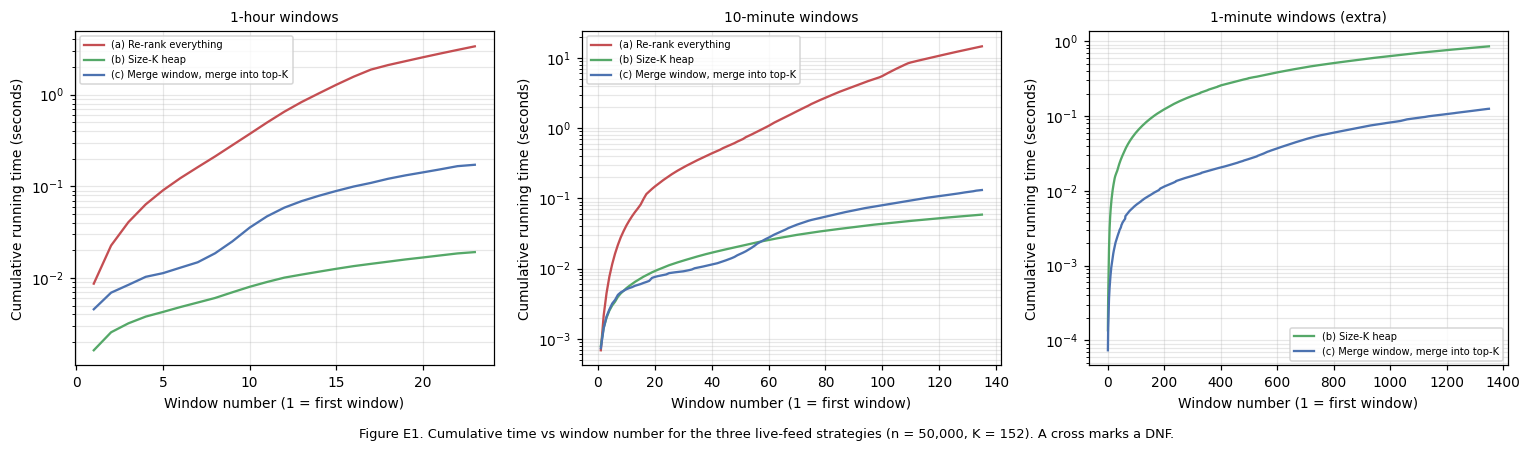

PEAK EXTRA MEMORY (tracemalloc, bytes)
                                    60s windows (bytes)  600s windows (bytes)  \
contender                                                                       
(a) Re-rank everything                              NaN             1045164.0   
(b) Size-K heap                               1771544.0              179288.0   
(c) Merge window, merge into top-K            3028766.0              669500.0   

                                    3600s windows (bytes)  
contender                                                  
(a) Re-rank everything                          1045568.0  
(b) Size-K heap                                   32152.0  
(c) Merge window, merge into top-K               452428.0  

TOTAL COST PER STRATEGY
                               contender  window status     time_s  \
148               (a) Re-rank everything    3600     OK   3.364615   
172                      (b) Size-K heap    3600     OK   0.019167   
196   (c) Merge wind

In [21]:
# Problem E - figures and memory
DF = STORE.df(); EC = DF[DF.problem == "E_curve"].copy(); EC["width"] = EC.window.astype(int)
E = DF[DF.problem == "E"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, (width, label) in zip(axes, [(3600, "1-hour windows"), (600, "10-minute windows"), (60, "1-minute windows (extra)")]):
    for sname in LIVE:
        x = EC[(EC.contender == sname) & (EC.width == width)].sort_values("idx")
        if x.empty: continue
        ax.plot(x.idx, x.time_s, color=LIVE_COL[sname], label=sname)
        row = E[(E.contender == sname) & (E.window == width)]
        if len(row) and row.iloc[0].status == "DNF":
            ax.scatter([x.idx.max()], [x.time_s.max()], marker="x", color=LIVE_COL[sname], s=80)
            ax.annotate(f"DNF; predicted total {row.iloc[0].time_s:.0f}s", (x.idx.max(), x.time_s.max()), fontsize=7, ha="right", va="bottom")
    ax.set_yscale("log"); ax.set_title(label, fontsize=9); ax.set_xlabel("Window number (1 = first window)"); ax.set_ylabel("Cumulative running time (seconds)"); ax.grid(alpha=.3, which="both"); ax.legend(fontsize=6.5)
fig.text(0.5, -0.03, f"Figure E1. Cumulative time vs window number for the three live-feed strategies (n = {E_N:,}, K = {K}). A cross marks a DNF.", ha="center", fontsize=8.5)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "fig_E1_live_feed.png"), bbox_inches="tight"); plt.show()
mem = DF[DF.problem == "E_mem"].pivot_table(index="contender", columns="window", values="peak_bytes")
mem.columns = [f"{int(c)}s windows (bytes)" for c in mem.columns]
print("PEAK EXTRA MEMORY (tracemalloc, bytes)"); display(mem.round(0)) if "display" in globals() else print(mem.round(0))
tot = E[["contender", "window", "status", "time_s", "comparisons", "moves", "correct"]].copy(); tot["window"] = tot.window.astype(int)
print("\nTOTAL COST PER STRATEGY"); display(tot.sort_values(["window", "contender"], ascending=[False, True])) if "display" in globals() else print(tot)
tot.to_csv(os.path.join(OUT_DIR, "table_E_totals.csv"), index=False)

## Problem F — the mathematical case
The derivations below are **drafts written for you to understand and re-write in your own words** (you will be asked about them in the viva). The code cells under M1, M5, M6, M7 compute the numbers you need (your `C5` sample, your band groups, your measured crossovers).

### M2 — Merge Sort: T(n) = 2T(n/2) + cn
**Iteration.** T(n) = 2T(n/2) + cn = 2[2T(n/4) + cn/2] + cn = 4T(n/4) + 2cn = 8T(n/8) + 3cn = … = 2^k T(n/2^k) + k·cn.
It stops at n/2^k = 1, i.e. k = log₂n, giving T(n) = n·T(1) + cn·log₂n = **Θ(n log n)**.
**Master theorem check.** a = 2, b = 2, f(n) = Θ(n) and n^(log_b a) = n^(log₂2) = n. Since f(n) = Θ(n^(log_b a)) this is **case 2**, so T(n) = Θ(n^(log_b a)·log n) = Θ(n log n). ✔ Same answer.

### M3 — Quick Sort
**(a) Worst case** (pivot is always the smallest or largest, e.g. sorted input with last-element pivot): T(n) = T(n−1) + cn.
Iteration: T(n) = T(n−2) + c(n−1) + cn = … = T(0) + c(1 + 2 + … + n) = c·n(n+1)/2 = **Θ(n²)**.
**(b) Best case** (perfect halves): T(n) = 2T(n/2) + cn. Recursion tree: level i has 2^i nodes each of size n/2^i, so every level costs 2^i·c·n/2^i = cn. The tree has log₂n + 1 levels, so T(n) = cn·(log₂n + 1) = **Θ(n log n)**.
**(c) 1 : 9 split:** T(n) = T(n/10) + T(9n/10) + n. Every level of the tree costs **at most n** (exactly n while all branches are still alive). The shallowest leaf is at depth log₁₀n (always taking the n/10 side), the deepest at depth log_{10/9}n (always taking the 9n/10 side).
Lower bound: the first log₁₀n levels are full and cost n each, so T(n) ≥ n·log₁₀n. Upper bound: T(n) ≤ n·(log_{10/9}n + 1).
Both bounds are constant multiples of n log n (log₁₀n = ln n/ln 10, log_{10/9}n = ln n/ln(10/9) ≈ 9.49 ln n), hence **T(n) = Θ(n log n)** — a constant-proportion split is as good as a perfect one asymptotically, only the constant is larger.

### M4 — Heap Sort
**Building the heap costs O(n).** Floyd's method calls sift-down on every internal node, from n/2 − 1 down to 0. A node of height h costs at most 2h comparisons (one to pick the larger child, one against the key, per level). There are at most ⌈n/2^(h+1)⌉ nodes of height h, so the cost is
Σ_{h=0}^{⌊log n⌋} ⌈n/2^(h+1)⌉·O(h) = O(n·Σ h/2^h) = O(n·2) = **O(n)** (the series Σ h/2^h converges to 2). Most nodes are near the leaves and sift very little; only one node (the root) can sift log n levels.
**Total cost.** Build O(n) + (n − 1) extractions, each a swap and a sift-down from the root costing at most 2·log₂n comparisons: O(n log n). Heap Sort is **Θ(n log n)** in the worst and average case (≈ 2n log₂n comparisons); with all keys equal the sift-downs stop immediately and it degenerates to Θ(n).

### M8 — space complexity (extra memory beyond the n records)
| contender | extra space | note |
|---|---|---|
| Insertion Sort | O(1) | one temporary record |
| Merge Sort | O(n) | copy of the left half at each merge (n/2 at the top) + O(log n) recursion |
| Naive Quick Sort | O(log n) | explicit stack, smaller part processed first. (A recursive version would use Θ(n) stack on sorted input.) |
| Hardened Quick Sort | O(log n) | same stack argument, random pivot |
| Heap Sort | O(1) | in place |
| Top-K (a) full sort + slice | O(n) | Merge Sort buffer |
| Top-K (b) size-K heap | O(K) | heap of K records |
| Top-K (c) insertion buffer | O(K) | sorted buffer of K records |
| Live (a) re-rank everything | O(n) | must keep every record seen, plus the sort buffer |
| Live (b) size-K heap | O(K) | heap + ranked copy |
| Live (c) merge window into top-K | O(W + K) | W = window size (sorted copy of the window) |

In [22]:
# M1 - insertion sort: inversions on your c5 sample
def count_inversions(a):
    """Pairs i<j with a[i] > a[j]; bottom-up merge counting, O(n log n). (Analysis tool, not a contender.)"""
    a = list(a); n = len(a); buf = a[:]; inv = 0; width = 1
    while width < n:
        for lo in range(0, n, 2 * width):
            mid = min(lo + width, n); hi = min(lo + 2 * width, n); i, j, k = lo, mid, lo
            while i < mid and j < hi:
                if a[j] < a[i]: buf[k] = a[j]; j += 1; inv += mid - i
                else: buf[k] = a[i]; i += 1
                k += 1
            while i < mid: buf[k] = a[i]; i += 1; k += 1
            while j < hi: buf[k] = a[j]; j += 1; k += 1
        a, buf = buf, a; width *= 2
    return inv

def insertion_prediction(seq):
    """Exact prediction for our insertion sort on distinct keys: comparisons = I + (n-1) - r, moves = I + t,
       r = #records smaller than everything before them, t = #records with a larger one before them."""
    n = len(seq); inv = count_inversions(seq); mn = mx = seq[0]; r = t = 0
    for x in seq[1:]:
        if x < mn: r += 1; mn = x
        if x < mx: t += 1
        else: mx = x
    return inv, inv + (n - 1) - r, inv + t

DF = STORE.df(); C = DF[DF.problem == "C"]; rows = []
for n in SIZES:
    pos = {r[1]: p for p, r in enumerate(get_input("C3", n))}
    for cond in ["C2", "C3", "C4", "C5"]:
        seq = [pos[r[1]] for r in get_input(cond, n)]; I, pc, pm = insertion_prediction(seq)
        m = C[(C.contender == "Insertion Sort") & (C.cond == cond) & (C.n == n) & (C.status == "OK")]
        rows.append({"n": n, "cond": f"{cond} {COND_NAME[cond]}", "inversions I": I, "n(n-1)/4": int(n * (n - 1) / 4), "n(n-1)/2": n * (n - 1) // 2,
                     "predicted comparisons": pc, "measured comparisons": int(m.iloc[0].comparisons) if len(m) else "DNF/not run",
                     "predicted moves": pm, "measured moves": int(m.iloc[0].moves) if len(m) else "DNF/not run"})
T_M1 = pd.DataFrame(rows); display(T_M1) if "display" in globals() else print(T_M1.to_string(index=False))
T_M1.to_csv(os.path.join(OUT_DIR, "table_M1_inversions.csv"), index=False)
c5 = T_M1[T_M1.cond.str.startswith("C5")]
print("\nM1 summary: best case (C3) I = 0 -> Theta(n);  worst case (C4) I = n(n-1)/2 -> Theta(n^2);  average case (random, C2) I ~ n(n-1)/4 -> Theta(n^2);")
print("running time = Theta(n + I) because the inner loop runs exactly once per inversion (one shift each) plus one comparison per element.")
print("C5 sample (1% of records moved):"); print(c5[["n", "inversions I", "predicted comparisons", "measured comparisons", "predicted moves", "measured moves"]].to_string(index=False))

   n              cond  inversions I  n(n-1)/4  n(n-1)/2  predicted comparisons  measured comparisons  predicted moves  measured moves
1000       C2 Shuffled        248252    249750    499500                 249243                249243           249245          249245
1000     C3 Pre-ranked             0    249750    499500                    999                   999                0               0
1000 C4 Reverse-ranked        499500    249750    499500                 499500                499500           500499          500499
1000  C5 Nearly ranked          3889    249750    499500                   4888                  4888             4715            4715
5000       C2 Shuffled       6278159   6248750  12497500                6283147               6283147          6283148         6283148
5000     C3 Pre-ranked             0   6248750  12497500                   4999                  4999                0               0
5000 C4 Reverse-ranked      12497500   6248750  1249750

In [23]:
# M5 - top-k cost model, predicted crossover vs measurement
def Hn(m): return math.log(m) + 0.5772156649 + 1 / (2 * m)                       # harmonic number
def cost_a(n): return n * math.log2(n) - 1.25 * n                                 # full Merge Sort (average comparisons)
def n_repl(n, k): return k * (Hn(n) - Hn(k))                                      # expected replacements for random order: K*(H_n - H_K)
def cost_b(n, k):                                                                 # heap: build ~2K + one root check per record + R sift-downs + rank the K survivors
    lk = math.log2(max(k, 2)); return 2 * k + (n - k) + n_repl(n, k) * 2 * lk + 2 * k * lk
def cost_c(n, k):                                                                 # buffer: fill ~K^2/4 + root check per record + R insertions of ~K/2 shifts
    return k * k / 4 + (n - k) + n_repl(n, k) * (k / 2 + 1)
print("M5 cost model (comparisons, random order):  (a) ~ n log2 n - 1.25n   (b) ~ n + 2 K ln(n/K) log2 K + 2K log2 K   (c) ~ n + (K^2/2) ln(n/K)")
print("worst cases: (a) Theta(n log n), (b) Theta(n log K) [every record beats the root], (c) Theta(n K) [every record shifts through the buffer]\n")
def first_k(f, n):
    for k in range(2, n // 2):
        if f(k): return k
    return None
for n in sorted(set([100000] + D_SIZES)):
    kbc = first_k(lambda k: cost_c(n, k) > cost_b(n, k), n); kab = first_k(lambda k: cost_b(n, k) > cost_a(n), n)
    print(f"n = {n:>7,}: predicted crossover (b)->(c): insertion buffer costs more than the heap from K ~ {kbc};   heap costs more than a full sort from K ~ {kab if kab else 'never below n/2'}")
DF = STORE.df(); D = DF[(DF.problem == "D") & (DF.status == "OK")]
print("\nMEASURED (Problem D): predicted vs measured comparisons, and who is faster")
rows = []
for (n, cond), g in D.groupby(["n", "cond"]):
    for k, gk in g.groupby("K"):
        d_ = {m: gk[gk.contender == m] for m in TOPK_METHODS}
        if any(len(v) == 0 for v in d_.values()): continue
        rows.append({"n": int(n), "cond": cond, "K": int(k),
                     "cmp (a) meas/pred": f"{int(d_['(a) Full sort + slice'].iloc[0].comparisons):,} / {int(cost_a(n)):,}",
                     "cmp (b) meas/pred": f"{int(d_['(b) Size-K heap'].iloc[0].comparisons):,} / {int(cost_b(n, k)):,}",
                     "cmp (c) meas/pred": f"{int(d_['(c) Insertion buffer'].iloc[0].comparisons):,} / {int(cost_c(n, k)):,}",
                     "faster (b) than (c)?": "yes" if d_['(b) Size-K heap'].iloc[0].time_s < d_['(c) Insertion buffer'].iloc[0].time_s else "NO",
                     "faster (b) than (a)?": "yes" if d_['(b) Size-K heap'].iloc[0].time_s < d_['(a) Full sort + slice'].iloc[0].time_s else "NO"})
T_M5 = pd.DataFrame(rows); display(T_M5) if "display" in globals() else print(T_M5.to_string(index=False)); T_M5.to_csv(os.path.join(OUT_DIR, "table_M5_predicted_vs_measured.csv"), index=False)
print("\nMeasured crossover (smallest K in the grid where the insertion buffer is slower than the heap) - compare with the prediction above:")
for (n, cond), g in D.groupby(["n", "cond"]):
    b_ = g[g.contender == "(b) Size-K heap"].set_index("K").time_s; c_ = g[g.contender == "(c) Insertion buffer"].set_index("K").time_s
    ks = sorted(set(b_.index) & set(c_.index)); slower = [k for k in ks if c_[k] > b_[k]]
    print(f"  n={int(n):>7,} {cond}: (c) slower than (b) from K = {int(slower[0]) if slower else 'never in the grid'}" + (f"  (last K where (c) was still faster: {int(max([k for k in ks if k < slower[0]], default=0)) or 'none'})" if slower else ""))
print("\nIf measurement and prediction disagree (they will, by a constant factor: shifting in a list is cheaper per step than a heap sift-down in Python), say so in the report and explain it.")

M5 cost model (comparisons, random order):  (a) ~ n log2 n - 1.25n   (b) ~ n + 2 K ln(n/K) log2 K + 2K log2 K   (c) ~ n + (K^2/2) ln(n/K)
worst cases: (a) Theta(n log n), (b) Theta(n log K) [every record beats the root], (c) Theta(n K) [every record shifts through the buffer]

n =  10,000: predicted crossover (b)->(c): insertion buffer costs more than the heap from K ~ 16;   heap costs more than a full sort from K ~ 1864
n =  50,000: predicted crossover (b)->(c): insertion buffer costs more than the heap from K ~ 16;   heap costs more than a full sort from K ~ 9320
n = 100,000: predicted crossover (b)->(c): insertion buffer costs more than the heap from K ~ 16;   heap costs more than a full sort from K ~ 18642

MEASURED (Problem D): predicted vs measured comparisons, and who is faster
    n cond    K cmp (a) meas/pred cmp (b) meas/pred       cmp (c) meas/pred faster (b) than (c)? faster (b) than (a)?
10000   C1   10 120,026 / 120,377   10,422 / 10,532         10,472 / 10,426           

In [24]:
# M6 - naive quick sort on c6 (band-only key)
# With the last element as pivot and a strict '<' Lomuto partition, every record equal to the pivot ends on the RIGHT of it.
# A group of m equal keys that has been separated from the other groups is an all-equal segment; sorting it costs
# (m-1) + (m-2) + ... + 1 = m(m-1)/2 comparisons. Before groups are separated, the segments are mixed and cost an extra
# R comparisons (R > 0, about "a few passes over the data").   Prediction:   comparisons ~ sum_i m_i (m_i - 1)/2  (+ R)
DF = STORE.df(); C = DF[DF.problem == "C"]; rows = []
for n in SIZES:
    from collections import Counter
    grp = Counter(r[0] for r in get_input("C6", n)); ms = [grp[k] for k in sorted(grp)]; d = len(ms)
    L = sum(m * (m - 1) // 2 for m in ms)
    q = C[(C.contender == "Naive Quick Sort") & (C.cond == "C6") & (C.n == n)]
    meas = int(q.iloc[0].comparisons) if len(q) and q.iloc[0].status == "OK" else None
    h = C[(C.contender == "Hardened Quick Sort") & (C.cond == "C6") & (C.n == n) & (C.status == "OK")]
    rows.append({"n": n, "d (groups)": d, "group sizes m_i": ms, "prediction L = sum m(m-1)/2": L, "n*d (scale of the mixed phase)": n * d,
                 "measured comparisons": meas if meas else "DNF/not run", "R = measured - L": (meas - L) if meas else "-",
                 "R / n": round((meas - L) / n, 2) if meas else "-", "measured / L": round(meas / L, 4) if meas else "-",
                 "Hardened Quick (3-way) comparisons": int(h.iloc[0].comparisons) if len(h) else "-"})
T_M6 = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 80)
display(T_M6) if "display" in globals() else print(T_M6.to_string(index=False)); T_M6.drop(columns=["group sizes m_i"]).to_csv(os.path.join(OUT_DIR, "table_M6_C6_naive_quick.csv"), index=False)
print("\nReading it: L is the quadratic part that the group sizes alone predict. The measured count is slightly above L; R = measured - L is the cost of the passes made while")
print("several groups were still mixed (each pass over a mixed segment of s records costs s-1). The three-way (hardened) quick sort does not pay m^2 because it puts the whole tie group in place in one pass.")
print("For n where the naive sort DNF'd, L is still the prediction: at n = 284,807 it is of the order of 10^10 comparisons, which explains the DNF.")

   n  d (groups)                         group sizes m_i  prediction L = sum m(m-1)/2  n*d (scale of the mixed phase)  measured comparisons  R = measured - L  R / n  measured / L  Hardened Quick (3-way) comparisons
1000           8       [5, 3, 8, 20, 103, 374, 359, 128]                       147624                            8000                149856              2232   2.23        1.0151                                3533
5000           8 [12, 30, 47, 114, 510, 1941, 1782, 564]                      3766225                           40000               3782721             16496   3.30        1.0044                               17569

Reading it: L is the quadratic part that the group sizes alone predict. The measured count is slightly above L; R = measured - L is the cost of the passes made while
several groups were still mixed (each pass over a mixed segment of s records costs s-1). The three-way (hardened) quick sort does not pay m^2 because it puts the whole tie group in place i

In [25]:
# M7 - live feed cost model and crossover
def live_costs(n, w, k):
    W = n / w; R = n_repl(n, k); lk = math.log2(max(k, 2))
    ms = lambda x: max(0.0, x * math.log2(max(x, 1)) - 1.25 * x)                  # Merge Sort comparisons on x records
    a = sum(ms(j * W) for j in range(1, w + 1))                                     # (a) sum_j merge sort of j*n/w records ~ n w log n / 2
    b = 2 * k + (n - k) + R * 2 * lk + w * 2 * k * lk                               # (b) n root checks + R sift-downs + w ranked snapshots of K
    c = w * ms(W) + w * k                                                           # (c) w window sorts of n/w records + w merges of <=K outputs
    return a, b, c
print("M7: total comparisons over w equal windows (n records, size-K queue)")
print("  (a) ~ sum_{j=1..w} (jn/w) log2(jn/w)  ~ (n w / 2) log2 n          = Theta(n w log n)")
print("  (b) ~ n + 2K ln(n/K) log2 K + w * 2K log2 K                          = Theta(n + w K log K)")
print("  (c) ~ n log2(n/w) + w K                                              = Theta(n log(n/w) + w K)")
n_ = E_N; grid = sorted(set([1, 2, 4, 8, 16, 24, 48, 96, 144, 288, 576, 1000, 2000, 2880, 5000, 10000]))
names = ["(a)", "(b)", "(c)"]; prev = None; print(f"\nPredicted cheapest strategy (n = {n_:,}, K = {K}):")
for w_ in grid:
    if w_ > n_: break
    costs = live_costs(n_, w_, K) if w_ <= 3000 else (float("inf"),) + live_costs(n_, w_, K)[1:]
    best = names[int(np.argmin(costs))]
    print(f"  w = {w_:>6}: (a)={costs[0]:>14,.0f}  (b)={costs[1]:>12,.0f}  (c)={costs[2]:>12,.0f}   -> {best}")
w_bc = next((w_ for w_ in range(2, min(E_N, 20000)) if live_costs(n_, w_, K)[2] < live_costs(n_, w_, K)[1]), None)
print(f"\nPREDICTED CROSSOVER: (b) is cheapest for w < {w_bc}; from about w = {w_bc} windows (windows of ~{n_ // w_bc if w_bc else '-'} records) strategy (c) becomes cheaper.")
print("(a) is only best when w = 1 (a single ranking). The crossover moves to LARGER w for smaller K (cheaper snapshots in (b)) and to smaller w for larger K.")
DF = STORE.df(); E = DF[DF.problem == "E"]; rows = []
for width in (3600, 600, 60):
    for sname in LIVE:
        r = E[(E.contender == sname) & (E.window == width)]
        if r.empty: continue
        r = r.iloc[0]; w_ = int(EC[(EC.contender == sname) & (EC.width == width)].idx.max()) if len(EC) else 0
        wtot = len(make_windows(E_RECORDS, width)); pr = live_costs(n_, wtot, K)["abc".index(sname[1])] if wtot <= 3000 or sname[1] != "a" else float("nan")
        rows.append({"window width": f"{width}s", "windows": wtot, "strategy": sname, "status": r.status,
                     "measured comparisons": int(r.comparisons) if r.status == "OK" else "partial (DNF)", "predicted comparisons": int(pr) if pr == pr else "-",
                     "time_s": round(r.time_s, 3)})
T_M7 = pd.DataFrame(rows); display(T_M7) if "display" in globals() else print(T_M7.to_string(index=False)); T_M7.to_csv(os.path.join(OUT_DIR, "table_M7_live_predicted_vs_measured.csv"), index=False)
t60 = E[E.window == 60]
if len(t60) == 2 and (t60.status == "OK").all():
    tb = float(t60[t60.contender.str.startswith("(b)")].time_s.iloc[0]); tc = float(t60[t60.contender.str.startswith("(c)")].time_s.iloc[0])
    print(f"\nCROSSOVER CHECK with 1-minute windows (w = {len(make_windows(E_RECORDS, 60))}): measured time (b) = {tb:.2f}s, (c) = {tc:.2f}s -> the cheaper strategy is {'(c)' if tc < tb else '(b)'};",
          "this" , "agrees" if ((tc < tb) == (len(make_windows(E_RECORDS, 60)) >= (w_bc or 10**9))) else "disagrees", "with the cost-model prediction. Explain any gap (Python constants) in the report.")

M7: total comparisons over w equal windows (n records, size-K queue)
  (a) ~ sum_{j=1..w} (jn/w) log2(jn/w)  ~ (n w / 2) log2 n          = Theta(n w log n)
  (b) ~ n + 2K ln(n/K) log2 K + w * 2K log2 K                          = Theta(n + w K log K)
  (c) ~ n log2(n/w) + w K                                              = Theta(n log(n/w) + w K)

Predicted cheapest strategy (n = 50,000, K = 152):
  w =      1: (a)=       717,982  (b)=      65,119  (c)=     718,134   -> (b)
  w =      2: (a)=     1,051,973  (b)=      67,322  (c)=     668,286   -> (b)
  w =      4: (a)=     1,729,391  (b)=      71,729  (c)=     618,590   -> (b)
  w =      8: (a)=     3,090,455  (b)=      80,542  (c)=     569,198   -> (b)
  w =     16: (a)=     5,816,471  (b)=      98,169  (c)=     520,414   -> (b)
  w =     24: (a)=     8,543,510  (b)=     115,796  (c)=     492,382   -> (b)
  w =     48: (a)=    16,725,801  (b)=     168,677  (c)=     446,030   -> (b)
  w =     96: (a)=    33,091,367  (b)=     274,439  (c)

## Problem G — change request
About 48 hours before the deadline the instructor posts a change request. Because everything is parameterised, you can answer it quickly:
1. Read the request, then change only what it changes (a different `K`, different window widths, a different key, another input condition, a memory limit …). All algorithms take the list of `(key, id)` records, so a new key only needs `_records()` / `_build()` to be changed.
2. Use the helper below for **fresh measurements** of any contender on any condition and size, with the same counters, the same DNF rule and the same correctness check.
3. In the report addendum say: **what changed**, **which earlier conclusions still hold and which do not**, and give the **fresh numbers** (the helper stores them in `results.csv` under problem `G`).

In [26]:
# Problem G helper - fresh measurements for the change request
def adhoc(cond="C2", n=None, contenders=None, runs=RUNS, tag="G"):
    """Run the chosen full sorts on (cond, n) with the same rules as Problem C and print a comparison table (stored as problem `tag`)."""
    n = n or SIZES[-1]; contenders = contenders or list(FULL_SORTS); rows = []
    for name in contenders:
        r = bench(tag, name, FULL_SORTS[name], cond, n, runs, TIME_LIMIT, extra_note=" | change request run") if not STORE.has(problem=tag, contender=name, cond=cond, n=n, K=None, window=None) else None
        d = STORE.df(); d = d[(d.problem == tag) & (d.contender == name) & (d.cond == cond) & (d.n == n)].iloc[0]
        rows.append({"contender": name, "status": d.status, "time_s": d.time_s, "comparisons": d.comparisons, "moves": d.moves, "correct": d.correct})
    return pd.DataFrame(rows)
# example (uncomment):  adhoc("C5", 10000)
print("helper ready: adhoc(cond, n, contenders=None) -> table; for live-feed changes call run_live(width, label, strategies) after editing the windows; for K changes edit K in cell 1 and rerun cells 14-16.")

helper ready: adhoc(cond, n, contenders=None) -> table; for live-feed changes call run_live(width, label, strategies) after editing the windows; for K changes edit K in cell 1 and rerun cells 14-16.


## Problem H — the recommendation (for the platform lead, not for your instructor)
The cell below **prints the evidence from your own results.csv** for each of the three jobs and a *draft* recommendation. Rewrite it in your own words, keep the three parts (evidence, assumption it depends on, one condition under which the recommendation is wrong) and keep it short. A vague or empty recommendation caps your whole assignment at 40 %.

In [27]:
# Problem H - evidence and draft recommendation
WRONG_IF = {
 "Merge Sort": ("memory for an extra n/2 records is available and the input is arbitrary or ties must keep their arrival order (it is stable)",
                "memory is tight (it needs O(n) extra space), or the day's file is already almost ranked, where an O(n + I) insertion pass is cheaper"),
 "Hardened Quick Sort": ("average-case speed matters more than a worst-case guarantee, and stability is not needed",
                         "equal-ranked records must keep arrival order (it is unstable), or an unlucky random-pivot sequence / adversarial pattern gives a quadratic run"),
 "Heap Sort": ("a guaranteed O(n log n) bound with O(1) extra memory is needed", "speed on typical data matters more - it makes ~2n log n comparisons with poor locality and is slower than Merge Sort here"),
 "Naive Quick Sort": ("the input is random", "the day's data arrives already ranked / reversed / with heavy ties, where it is quadratic"),
 "Insertion Sort": ("the data is almost ranked", "the data is shuffled - it needs about n^2/4 comparisons and moves"),
}
DF = STORE.df()
Cc = DF[(DF.problem == "C") & (DF.status == "OK")]
print("=" * 100); print("EVIDENCE FROM YOUR MEASUREMENTS"); print("=" * 100)
# job 1: overnight batch
cands = [(n, c) for n in sorted(Cc.n.unique(), reverse=True) for c in ["C1"] if Cc[(Cc.n == n) & (Cc.cond == c)].contender.nunique() >= 3]
nb = cands[0][0] if cands else int(Cc.n.max())
g1 = Cc[(Cc.n == nb) & (Cc.cond == "C1")].sort_values("time_s")
dnf1 = DF[(DF.problem == "C") & (DF.n == nb) & (DF.cond == "C1") & DF.status.str.startswith("DNF")].contender.tolist()
print(f"\nJOB 1 - overnight batch (a full day, arrival order C1, n = {nb:,})")
print(g1[["contender", "time_s", "comparisons", "moves"]].to_string(index=False)); print("DNF:", ", ".join(dnf1) if dnf1 else "none")
best1 = g1.iloc[0].contender if len(g1) else "Merge Sort"
# worst measured time across the n log n contenders on all conditions at nb (robustness)
rob = Cc[(Cc.n == nb) & Cc.contender.isin([best1])].groupby("cond").time_s.max()
print(f"{best1} across all conditions at n = {nb:,} (s):", {k: round(v, 3) for k, v in rob.items()})
# job 2: shift queue
Dd = DF[(DF.problem == "D") & (DF.status == "OK")]; nd = int(Dd.n.max()) if len(Dd) else None
if nd:
    g2 = Dd[(Dd.n == nd) & (Dd.K == K) & (Dd.cond == "C1")].sort_values("time_s")
    print(f"\nJOB 2 - shift queue (K = {K}, n = {nd:,}, C1)"); print(g2[["contender", "time_s", "comparisons", "moves"]].to_string(index=False))
    best2 = g2.iloc[0].contender
# job 3: live
Ee = DF[(DF.problem == "E")]
print("\nJOB 3 - live refresh (n = %s, K = %d)" % (f"{E_N:,}", K))
print(Ee[["contender", "window", "status", "time_s", "comparisons"]].assign(window=lambda x: x.window.astype(int)).sort_values(["window", "time_s"], ascending=[False, True]).to_string(index=False))
Em = DF[DF.problem == "E_mem"]; print("peak memory (bytes):"); print(Em.pivot_table(index="contender", columns="window", values="peak_bytes").round(0).to_string())
e_ok = Ee[(Ee.window == 3600) & (Ee.status == "OK")].sort_values("time_s"); best3 = e_ok.iloc[0].contender if len(e_ok) else "(b) Size-K heap"

print("\n" + "=" * 100); print("DRAFT RECOMMENDATION - rewrite in your own words, keep evidence + assumption + 'wrong if'"); print("=" * 100)
a1, w1 = WRONG_IF.get(best1, ("-", "-"))
print(f"\n1. Overnight batch: ship {best1}.\n   Evidence: fastest finisher at n = {nb:,} on arrival-order data ({fmt_t(g1.iloc[0].time_s) if len(g1) else '-'}); Insertion/Naive Quick are Theta(n^2) on this data (see DNFs and Figure C1/C2); M2/M4 give Theta(n log n).\n   Assumption: {a1}.\n   Wrong if: {w1}.")
if nd:
    print(f"\n2. Shift queue of K = {K}: ship {best2}.\n   Evidence: fastest at n = {nd:,}, K = {K} ({fmt_t(g2.iloc[0].time_s)}); Problem D tables give the K at which the best method changes; M5 predicts the same ordering.\n   Assumption: K << n and the records arrive in no special order (expected replacements K ln(n/K) stay small).\n   Wrong if: K grows toward n/10 or beyond (a full sort wins), or the data arrives so that every record beats the current worst (reverse-ranked: the heap does n log K work, the buffer n*K).")
LIVE_WHY = {"(a)": ("it is the simplest and always correct", "w is small (a handful of windows), where one re-rank is cheaper than bookkeeping", "O(n) memory"),
            "(b)": ("lowest cumulative time at 1-hour and 10-minute windows (Figure E1) and only O(K) extra memory", f"windows become very small (w beyond the M7 crossover ~{w_bc}): publishing a ranked copy of the heap every window costs w K log K, and merging a sorted window into the top-K (c) is cheaper", "O(K) memory"),
            "(c)": ("lowest cumulative time at 1-hour and 10-minute windows (Figure E1)", "windows hold fewer records than about K, or memory for a sorted copy of one window is not available", "O(W + K) memory")}
ev3, wr3, mm3 = LIVE_WHY[best3[:3]]
print(f"\n3. Live refresh: ship {best3}.\n   Evidence: {ev3}; re-ranking everything costs Theta(n w log n) (M7) and is the slowest or DNF. Memory: {mm3} (measured table above).\n   Assumption: windows hold many more records than K and w is moderate (here w <= 288).\n   Wrong if: {wr3}.")

EVIDENCE FROM YOUR MEASUREMENTS

JOB 1 - overnight batch (a full day, arrival order C1, n = 5,000)
          contender   time_s  comparisons     moves
   Naive Quick Sort 0.017111      68901.0   53386.0
         Merge Sort 0.021437      55112.0   87659.0
          Heap Sort 0.023676     107834.0   69278.0
Hardened Quick Sort 0.025799      97232.0  135090.0
     Insertion Sort 1.449266    5698515.0 5698518.0
DNF: none
Naive Quick Sort across all conditions at n = 5,000 (s): {'C1': 0.017, 'C2': 0.016, 'C3': 2.576, 'C4': 2.101, 'C5': 0.412, 'C6': 0.32}

JOB 2 - shift queue (K = 152, n = 50,000, C1)
            contender   time_s  comparisons     moves
      (b) Size-K heap 0.012755      63212.0    8667.0
 (c) Insertion buffer 0.027537     128334.0   78495.0
(a) Full sort + slice 0.294946     716352.0 1126522.0

JOB 3 - live refresh (n = 50,000, K = 152)
                         contender  window status    time_s  comparisons
                   (b) Size-K heap    3600     OK  0.019167     

## AI-use disclosure (required paragraph — edit to match what *you* actually did)
> I used an AI assistant (Claude) to help generate the readme and results.csv as i didn;t know most of that syntax, i build my logic myself and understood the concepts through youtuibe and then tried implementing them and used claude to write code where i couldn't, trace errors, run files when they weren't and reviewing that i was following the guidelines


In [28]:
# Create and download README.md and results.csv
import shutil
NAME = f"{ROLL}-A2-{SECTION}"          # naming convention: RollNo-A2-Section
README = f"""# {NAME} - The Midnight Queue (DAA Assignment 2)

Roll no: {ROLL}   Section: {SECTION}   Seed s = {SEED}   K = {K}

## Files
- {NAME}.ipynb / {NAME}.py : all code (algorithms, tests, experiments)
- results.csv : every measurement (one row per measurement)
- prediction_log.txt : prediction log written before the tournament
- README.md : this file

## How to reproduce
1. Download creditcard.csv from Kaggle (mlg-ulb/creditcardfraud). It is not included in this submission.
2. Open the notebook in Google Colab or Jupyter. Put creditcard.csv next to it (or let the notebook download it).
3. Set MODE = "full" in the settings cell (sizes 1,000 / 10,000 / 100,000 / 284,807, 5 runs, 300 s DNF limit).
4. Edit the prediction log cell, then Run all. Results are appended to results.csv, so a stopped run resumes.
5. Run the last cell to create README.md and results.csv.

## Settings
- Python 3, numpy and pandas (loading data and risk score only); no built-in sort inside any contender.
- sorted() is used only to verify outputs and to build the C3 input.
- Seed {SEED}, K = 25 + ({SEED} mod 226) = {K}.
- Hardware/software: {HARDWARE}
- This run used MODE = {MODE}.
"""
open("README.md", "w").write(README)
shutil.copy(os.path.join(OUT_DIR, "results.csv"), "results.csv")
print("created README.md and results.csv")
if IN_COLAB:
    from google.colab import files
    files.download("README.md"); files.download("results.csv")


created README.md and results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>